# 01_market — рынок: таможня Кореи (роль A, Гузель)

**Вопросы ноутбука:** 1 — в какую страну заходить; 5а/5б — когда запускаться; итоговый календарь запуска.

**Этот раздел — Data preprocessing.** Из таможенной статистики Кореи (관세청, HS 3304) собираем чистую таблицу `customs_clean.csv` для всей команды (её использует Жулдыз в вопросе 2).

Решения, принятые в ТЗ (раздел 16):
- основная метрика — **тонны** (`수출 중량`); доллары искажают курс и рост цен;
- одна строка = страна × месяц, 2015-01 … 2026-10, пропущенные месяцы = 0;
- группы: Россия, другие СНГ, Беларусь и Монголия отдельно, Китай отдельно, «мир без СНГ и Китая» — одной суммарной строкой.

In [1]:
import pandas as pd, numpy as np
from pathlib import Path
pd.set_option('display.width', 160)

# данные лежат в data/raw/ (после реорганизации репозитория) или пока в корне репозитория
CANDIDATES = [Path('../data/raw'), Path('..'), Path('.')]
def find(name):
    for d in CANDIDATES:
        if (d / name).exists():
            return d / name
    raise FileNotFoundError(name)

CLEAN = Path('../data/clean'); CLEAN.mkdir(parents=True, exist_ok=True)
world_path = find('customs_HS3304_WORLD_2015-01_2026-10.csv')
cis_path   = find('customs_HS3304_CIS_2015-01_2026-10.csv')
world_path, cis_path

(PosixPath('../data/raw/customs_HS3304_WORLD_2015-01_2026-10.csv'),
 PosixPath('../data/raw/customs_HS3304_CIS_2015-01_2026-10.csv'))

## 1.1. Загрузка
Берём файл **WORLD** (все 228 стран): в нём есть и страны региона, и Таджикистан, Туркменистан, Молдова, которых нет в CIS-файле, и всё остальное для контрольной группы. CIS-файл используем только для проверки.

In [2]:
read = lambda p: pd.read_csv(p, encoding='utf-8-sig', dtype={'HS코드': str})
world, cis = read(world_path), read(cis_path)
print(world.shape, cis.shape)
print('период:', world['기간'].min(), '…', world['기간'].max(), '| месяцев:', world['기간'].nunique())
print('строки «총계» (итог):', (world['기간'] == '총계').sum(), '| полные дубли:', world.duplicated().sum(),
      '| дубли страна×месяц:', world.duplicated(['기간', '국가']).sum())
world.head(3)

(19003, 9) (1254, 9)
период: 2015-01 … 2026-10 | месяцев: 142
строки «총계» (итог): 0 | полные дубли: 0 | дубли страна×месяц: 0


,기간,국가,HS코드,품목명,수출 중량,수출 금액,수입 중량,수입 금액,무역수지
0,2015-01,괌,3304,"미용이나 메이크업용 제품류와 기초화장용 제품류[의약품은 제외하며, 선스크린(suns...",0.1,8,0.0,0,8
1,2015-01,그리스,3304,"미용이나 메이크업용 제품류와 기초화장용 제품류[의약품은 제외하며, 선스크린(suns...",0.0,2,0.1,1,1
2,2015-01,기타국,3304,"미용이나 메이크업용 제품류와 기초화장용 제품류[의약품은 제외하며, 선스크린(suns...",0.0,1,0.0,0,1


## 1.2. Названия стран → коды
Корейские названия переводим в коды ISO. Ловушки: `투르크 & 카이코스 군도` — острова Теркс и Кайкос (не Туркменистан), `남조지아 & 남샌드위치 군도` — Южная Георгия (не Грузия), `기타국` — «прочие страны» (не страна, идёт в «мир»).

**Почему такие группы:**
- **Беларусь отдельно** — сама под санкциями с 2022 года и с крошечной базой (~5 млн $ в год), поэтому не годится в контроль для России;
- **Китай отдельно** — экспорт туда упал вдвое по своим причинам и исказил бы «мир»;
- **Монголия отдельно** — не СНГ, но в нашем регионе;
- **Украину** не включаем ни в одну группу.

In [3]:
COUNTRY_MAP = {  # корейское название: (iso2, iso3, по-русски, группа)
    '러시아 연방': ('RU', 'RUS', 'Россия', 'RU'),
    '카자흐스탄': ('KZ', 'KAZ', 'Казахстан', 'other_CIS'),
    '키르기스스탄': ('KG', 'KGZ', 'Кыргызстан', 'other_CIS'),
    '우즈베키스탄': ('UZ', 'UZB', 'Узбекистан', 'other_CIS'),
    '아르메니아': ('AM', 'ARM', 'Армения', 'other_CIS'),
    '아제르바이잔': ('AZ', 'AZE', 'Азербайджан', 'other_CIS'),
    '조지아': ('GE', 'GEO', 'Грузия', 'other_CIS'),
    '타지크': ('TJ', 'TJK', 'Таджикистан', 'other_CIS'),
    '투르크멘': ('TM', 'TKM', 'Туркменистан', 'other_CIS'),
    '몰도바': ('MD', 'MDA', 'Молдова', 'other_CIS'),
    '벨라루스': ('BY', 'BLR', 'Беларусь', 'BY'),
    '몽골': ('MN', 'MNG', 'Монголия', 'MN'),
    '중국': ('CN', 'CHN', 'Китай', 'CN'),
}
EXCLUDE = {'우크라이나'}  # Украина — ни в одну группу

missing = [k for k in COUNTRY_MAP if k not in set(world['국가'])]
print('не найдены в данных:', missing)
print('похожие названия-ловушки в данных:', [c for c in world['국가'].unique() if ('투르크' in c or '조지아' in c) and c not in COUNTRY_MAP])

не найдены в данных: []
похожие названия-ловушки в данных: ['남조지아 & 남샌드위치 군도', '투르크 & 카이코스 군도']


## 1.3. Сборка таблицы «страна × месяц»
Страны из списка — отдельными строками; все остальные (кроме Украины) складываем в одну строку **WX = мир без СНГ и Китая**.

In [4]:
w = world[~world['국가'].isin(EXCLUDE)].copy()
w['iso2'] = w['국가'].map(lambda c: COUNTRY_MAP[c][0] if c in COUNTRY_MAP else 'WX')
agg = (w.groupby(['기간', 'iso2'], as_index=False)[['수출 중량', '수출 금액']].sum()
         .rename(columns={'기간': 'month', '수출 중량': 'tons', '수출 금액': 'usd_k'}))

META = pd.DataFrame([(v[0], v[1], v[2], v[3]) for v in COUNTRY_MAP.values()] + [('WX', '', 'Мир без СНГ и Китая', 'world_ex')],
                    columns=['iso2', 'iso3', 'country_ru', 'group'])

# полная сетка: каждый месяц × каждая страна; месяцы без экспорта = 0
months = pd.period_range('2015-01', '2026-10', freq='M').strftime('%Y-%m')
grid = pd.MultiIndex.from_product([months, META['iso2']], names=['month', 'iso2']).to_frame(index=False)
df = grid.merge(agg, on=['month', 'iso2'], how='left')
n_filled = df['tons'].isna().sum()
df[['tons', 'usd_k']] = df[['tons', 'usd_k']].fillna(0)
df = df.merge(META, on='iso2')
print('строк:', len(df), '| заполнено нулями пар страна×месяц:', n_filled)
print(df.loc[df['tons'].eq(0)].groupby('country_ru').size().sort_values(ascending=False).to_string())

строк: 1988 | заполнено нулями пар страна×месяц: 143
country_ru
Таджикистан     95
Туркменистан    49
Грузия          24
Армения         21
Молдова         12
Беларусь        10
Азербайджан      6
Узбекистан       2


**Почему пропуски = 0.** Таможня публикует строку только если в этот месяц в страну что-то экспортировали. Пустые месяцы — это отсутствие экспорта, а не потерянные данные (все они в 2015–2018 годах и у маленьких рынков).

## 1.4. Производные колонки
- `usd_per_kg` — цена за кг ($/кг): тыс. $ / тонны = $/кг. Показывает, насколько «дорогой» рынок. Где тонн 0 — пусто.
- `tons_yoy` — рост в тоннах к тому же месяцу год назад (убирает сезонность). Где год назад было 0 — пусто.
- `post_2022` — 1 начиная с марта 2022 (санкции).

In [5]:
df = df.sort_values(['iso2', 'month']).reset_index(drop=True)
df['usd_per_kg'] = np.where(df['tons'] > 0, df['usd_k'] / df['tons'], np.nan)
prev = df.groupby('iso2')['tons'].shift(12)
df['tons_yoy'] = np.where(prev > 0, df['tons'] / prev - 1, np.nan)
df['post_2022'] = (df['month'] >= '2022-03').astype(int)

COLS = ['month', 'iso2', 'iso3', 'country_ru', 'group', 'tons', 'usd_k', 'usd_per_kg', 'tons_yoy', 'post_2022']
df = df[COLS]
df.head()

,month,iso2,iso3,country_ru,group,tons,usd_k,usd_per_kg,tons_yoy,post_2022
0,2015-01,AM,ARM,Армения,other_CIS,0.9,26.0,28.888889,NaN,0
1,2015-02,AM,ARM,Армения,other_CIS,0.1,9.0,90.000000,NaN,0
2,2015-03,AM,ARM,Армения,other_CIS,0.1,10.0,100.000000,NaN,0
3,2015-04,AM,ARM,Армения,other_CIS,0.1,3.0,30.000000,NaN,0
4,2015-05,AM,ARM,Армения,other_CIS,0.0,0.0,NaN,NaN,0


## 1.5. Проверки
1. Сумма тонн и долларов совпадает с исходным файлом (минус Украина) — ничего не потеряли и не задвоили.
2. Страны региона совпадают с CIS-файлом.
3. Контрольные цифры по годам.

In [6]:
raw_tot = world.loc[~world['국가'].isin(EXCLUDE), ['수출 중량', '수출 금액']].sum()
print('тонны: исходник %.1f | чистый %.1f' % (raw_tot['수출 중량'], df['tons'].sum()))
print('тыс. $: исходник %.0f | чистый %.0f' % (raw_tot['수출 금액'], df['usd_k'].sum()))
assert np.isclose(raw_tot['수출 중량'], df['tons'].sum()) and np.isclose(raw_tot['수출 금액'], df['usd_k'].sum())

c = cis.assign(iso2=cis['국가'].map(lambda x: COUNTRY_MAP[x][0])).rename(columns={'기간': 'month'})
chk = c.merge(df, on=['month', 'iso2'])
print('строк CIS сверено:', len(chk), '| расхождений по тоннам:', (~np.isclose(chk['수출 중량'], chk['tons'])).sum())
assert len(chk) == len(cis) and np.isclose(chk['수출 중량'], chk['tons']).all()
assert df.duplicated(['month', 'iso2']).sum() == 0 and len(df) == 142 * 14

yearly = df[df['month'] < '2026'].assign(year=lambda d: d['month'].str[:4]).pivot_table(index='country_ru', columns='year', values='tons', aggfunc='sum')
(yearly[['2017', '2021', '2022', '2023', '2024', '2025']] / 1000).round(1)  # тыс. тонн

тонны: исходник 2541537.0 | чистый 2541537.0
тыс. $: исходник 75446490 | чистый 75446490
строк CIS сверено: 1254 | расхождений по тоннам: 0


year,2017,2021,2022,2023,2024,2025
country_ru,,,,,,
Азербайджан,0.0,0.0,0.1,0.1,0.1,0.1
Армения,0.0,0.0,0.1,0.1,0.0,0.0
Беларусь,0.0,0.1,0.3,0.2,0.2,0.2
Грузия,0.0,0.1,0.1,0.1,0.1,0.1
Казахстан,0.5,1.4,1.6,1.8,2.4,3.3
Китай,54.3,125.5,85.4,74.1,61.0,55.8
Кыргызстан,0.4,2.7,2.9,2.6,2.6,2.9
Мир без СНГ и Китая,84.3,109.0,108.8,135.2,178.5,212.6
Молдова,0.0,0.1,0.1,0.2,0.2,0.2


## 1.6. Сохранение
`data/clean/customs_clean.csv` — для всей команды (колонки строго по ТЗ, раздел 16.2).

In [7]:
out = CLEAN / 'customs_clean.csv'
df.to_csv(out, index=False, encoding='utf-8-sig')
print(out, df.shape)
df.describe(include='all').T[['count', 'unique', 'mean', 'min', 'max']]

../data/clean/customs_clean.csv (1988, 10)


,count,unique,mean,min,max
month,1988,142,NaN,NaN,NaN
iso2,1988,14,NaN,NaN,NaN
iso3,1988,14,NaN,NaN,NaN
country_ru,1988,14,NaN,NaN,NaN
group,1988,6,NaN,NaN,NaN
tons,1988.0,NaN,1278.439135,0.0,26889.3
usd_k,1988.0,NaN,37950.950704,0.0,935942.0
usd_per_kg,1769.0,NaN,41.62401,0.0,460.0
tons_yoy,1608.0,NaN,1.557489,-1.0,153.0
post_2022,1988.0,NaN,0.394366,0.0,1.0


# 2. EDA — вопрос 1: в какую страну заходить

Смотрим 9 стран региона (Таджикистан, Туркменистан и Молдова — слишком маленькие рынки, только в контексте). Считаем 5 метрик, по которым потом построим рейтинг:

| Метрика | Что показывает | Как считаем |
|---|---|---|
| объём 2025 | размер рынка сейчас | тонны за 2025 год |
| рост (CAGR 2021–2025) | куда движется рынок | среднегодовой рост тонн |
| стабильность | насколько предсказуем | коэффициент вариации месячных тонн в 2025 (меньше = стабильнее) |
| $/кг | дорогой или массовый рынок | средняя цена за кг в 2025 |
| тонн на млн жителей | насколько рынок насыщен | тонны 2025 / население (World Bank) |

In [8]:
import matplotlib.pyplot as plt
from scipy import stats
FIG = Path('../figures'); FIG.mkdir(exist_ok=True)
PALETTE = {'RU': '#D55E00', 'KZ': '#0072B2', 'KG': '#009E73', 'UZ': '#E69F00', 'BY': '#CC79A7', 'MN': '#56B4E9',
           'AM': '#999999', 'AZ': '#999999', 'GE': '#999999', 'CN': '#7F7F7F', 'WX': '#000000'}
REGION = ['RU', 'KZ', 'KG', 'UZ', 'AM', 'AZ', 'GE', 'BY', 'MN']

cc = pd.read_csv(CLEAN / 'customs_clean.csv', encoding='utf-8-sig')
cc['year'] = cc['month'].str[:4].astype(int)
wb = pd.read_csv(find('06_worldbank_countries_monthly.csv'))
pop = wb.groupby(['iso3', 'year'])['population'].first().unstack()
name = cc.drop_duplicates('iso2').set_index('iso2')['country_ru']

## 2.1. Распределение: почему логарифм
Россия и «мир» на порядки больше маленьких стран — распределение с длинным хвостом. На обычной шкале маленькие страны сливаются с нулём, поэтому для графиков и регрессий берём log.

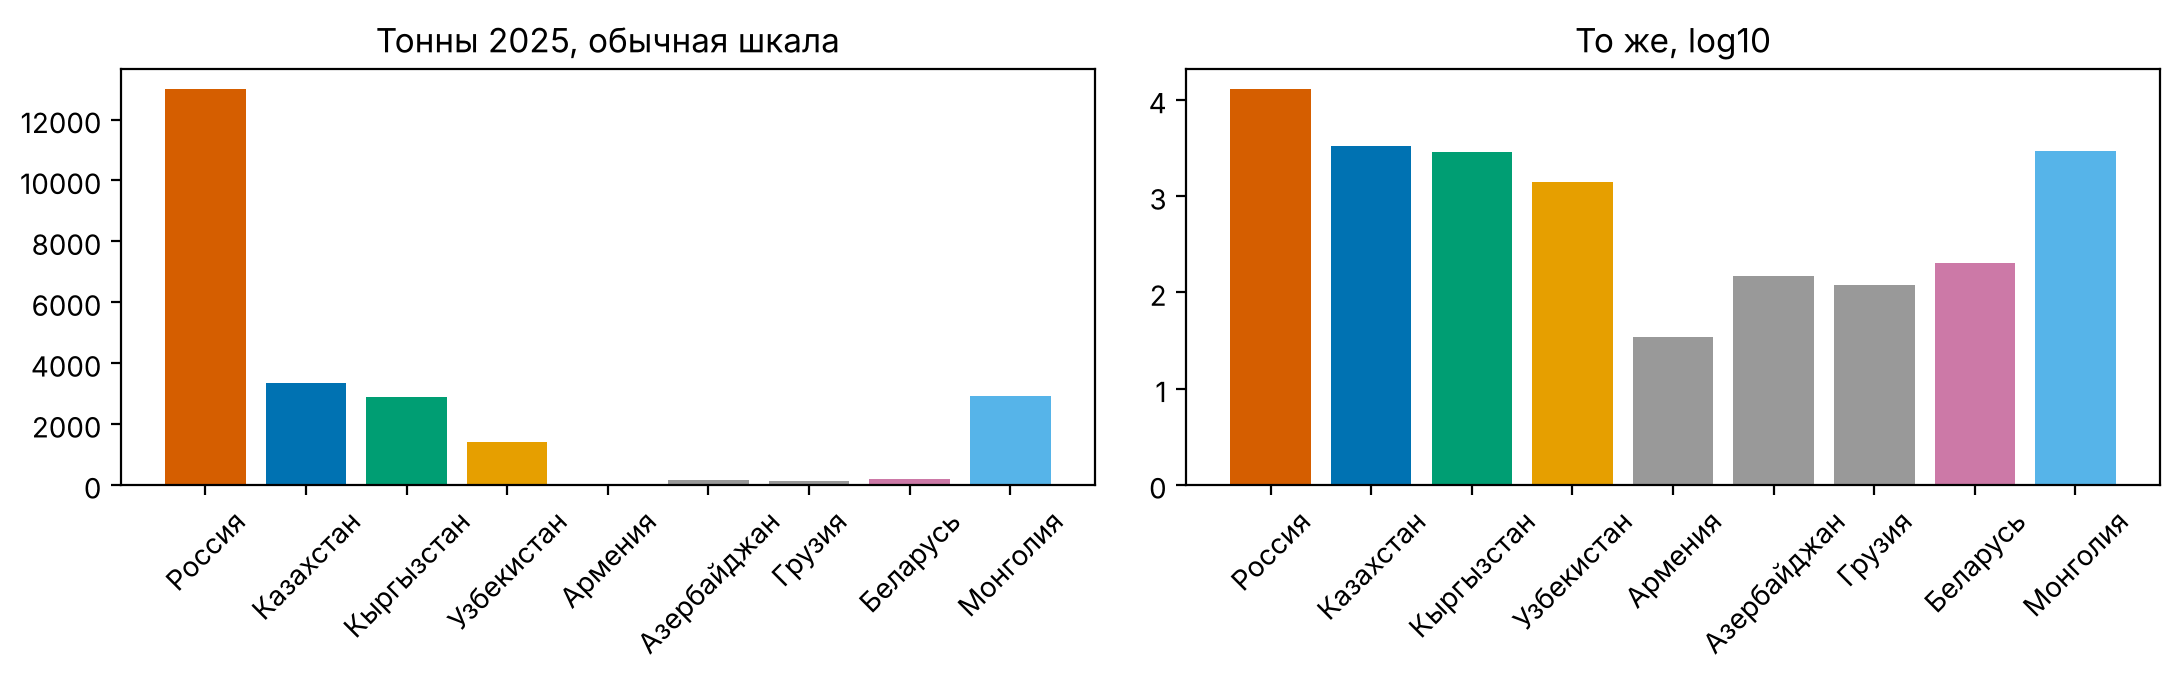

iso2
RU    54.1
KZ    13.9
KG    12.0
UZ     5.9
AM     0.1
AZ     0.6
GE     0.5
BY     0.8
MN    12.1


In [9]:
y25 = cc[cc['year'] == 2025]
tons25 = y25.groupby('iso2')['tons'].sum().reindex(REGION)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar([name[i] for i in REGION], tons25, color=[PALETTE[i] for i in REGION]); ax[0].set_title('Тонны 2025, обычная шкала')
ax[1].bar([name[i] for i in REGION], np.log10(tons25 + 1), color=[PALETTE[i] for i in REGION]); ax[1].set_title('То же, log10')
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
print((tons25 / tons25.sum() * 100).round(1).rename('доля региона, %').to_string())

## 2.1b. Выбросы (IQR): помечаем, не удаляем
Ищем месяцы, которые сильно выбиваются из своего обычного уровня. Чтобы рост рынка не выглядел как выброс, считаем отношение месяца к центрированному скользящему среднему за 12 месяцев и применяем правило IQR: выброс — ниже Q1 − 1,5·IQR или выше Q3 + 1,5·IQR. Выбросы **не удаляем**: это реальные события (шок марта 2022, разовые крупные поставки), а для небольших рынков — шум маленьких чисел.

In [10]:
BIG5 = ['RU', 'KZ', 'KG', 'UZ', 'MN']
w5 = cc[cc['iso2'].isin(BIG5) & (cc['month'] >= '2016-07')].pivot_table(index='month', columns='iso2', values='tons')[BIG5]
r5 = w5 / ((w5.rolling(12, center=True).mean() + w5.rolling(12, center=True).mean().shift(-1)) / 2)
r5 = r5[r5.index >= '2017-01'].dropna(how='all')
out_rows = []
for i in BIG5:
    s = r5[i].dropna(); q1, q3 = s.quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    for m_, v in s[(s < lo) | (s > hi)].items():
        out_rows.append([name[i], m_, round(v, 2), 'ниже обычного' if v < lo else 'выше обычного'])
outliers = pd.DataFrame(out_rows, columns=['страна', 'месяц', 'отношение к обычному уровню', 'направление'])
print('всего выбросов:', len(outliers), 'из', r5.notna().sum().sum(), 'страна-месяцев')
outliers.sort_values(['страна', 'месяц'])

всего выбросов: 17 из 560 страна-месяцев


,страна,месяц,отношение к обычному уровню,направление
4,Казахстан,2017-08,1.76,выше обычного
5,Казахстан,2017-10,0.26,ниже обычного
6,Казахстан,2018-02,0.18,ниже обычного
7,Казахстан,2019-09,1.68,выше обычного
8,Кыргызстан,2020-04,0.05,ниже обычного
11,Монголия,2019-05,1.91,выше обычного
12,Монголия,2019-07,2.56,выше обычного
13,Монголия,2020-04,1.63,выше обычного
14,Монголия,2020-05,1.90,выше обычного
15,Монголия,2020-11,0.28,ниже обычного


**Как читать:** выбросов немного, и они объяснимы. Для России главный — **март 2022** (поставки вдвое ниже обычного уровня в первый месяц санкций). У Центральной Азии и Монголии выбросы чаще: рынки меньше, одна крупная поставка заметно сдвигает месяц. Поэтому мы их оставляем, а в моделях работаем с логарифмом и устойчивыми ошибками (HC1), на которые отдельные выбросы влияют слабо.

## 2.2. Пять метрик по странам

In [11]:
def cagr(s, a, b):
    return (s[b] / s[a]) ** (1 / (b - a)) - 1 if s[a] > 0 else np.nan

ann = cc.pivot_table(index='iso2', columns='year', values='tons', aggfunc='sum')
m = pd.DataFrame(index=REGION)
m['страна'] = [name[i] for i in REGION]
m['тонн_2025'] = ann.loc[REGION, 2025]
m['рост_2021_25_%'] = [cagr(ann.loc[i], 2021, 2025) * 100 for i in REGION]
m['рост_2017_21_%'] = [cagr(ann.loc[i], 2017, 2021) * 100 for i in REGION]
mon25 = y25.pivot_table(index='month', columns='iso2', values='tons')[REGION]
m['нестабильность_CV'] = (mon25.std() / mon25.mean()).values
usd25 = y25.groupby('iso2')[['usd_k', 'tons']].sum().reindex(REGION)
m['usd_за_кг'] = usd25['usd_k'] / usd25['tons']
iso3 = cc.drop_duplicates('iso2').set_index('iso2')['iso3']
m['тонн_на_млн_жит'] = m['тонн_2025'] / (pop.loc[iso3[REGION].values, 2025].values / 1e6)
metrics = m.round(2)
metrics.sort_values('тонн_2025', ascending=False)

,страна,тонн_2025,рост_2021_25_%,рост_2017_21_%,нестабильность_CV,usd_за_кг,тонн_на_млн_жит
RU,Россия,13011.4,2.37,35.88,0.16,27.76,90.66
KZ,Казахстан,3343.9,25.29,31.57,0.26,32.16,160.43
MN,Монголия,2917.9,36.57,15.18,0.21,15.40,817.57
KG,Кыргызстан,2877.4,1.97,57.31,0.16,28.54,391.85
UZ,Узбекистан,1410.6,32.77,59.87,0.28,25.61,38.07
BY,Беларусь,200.5,10.11,121.17,0.82,26.15,22.07
AZ,Азербайджан,147.1,49.43,58.28,0.33,45.29,14.36
GE,Грузия,119.5,15.87,137.04,0.64,59.56,30.36
AM,Армения,33.2,-5.99,123.61,0.85,39.55,10.76


**Как читать:** Россия — самый большой рынок, но рост в тоннах почти остановился. Центральная Азия маленькая, но растёт быстрее. Высокий экспорт на жителя в Кыргызстане и Монголии подозрителен для таких небогатых стран — гипотеза: часть товара идёт дальше транзитом (в Россию и Китай). Узбекистан — большая страна с низким потреблением на жителя: рынок, где есть куда расти.

## 2.3. Доллары против тонн (зацепка проекта)

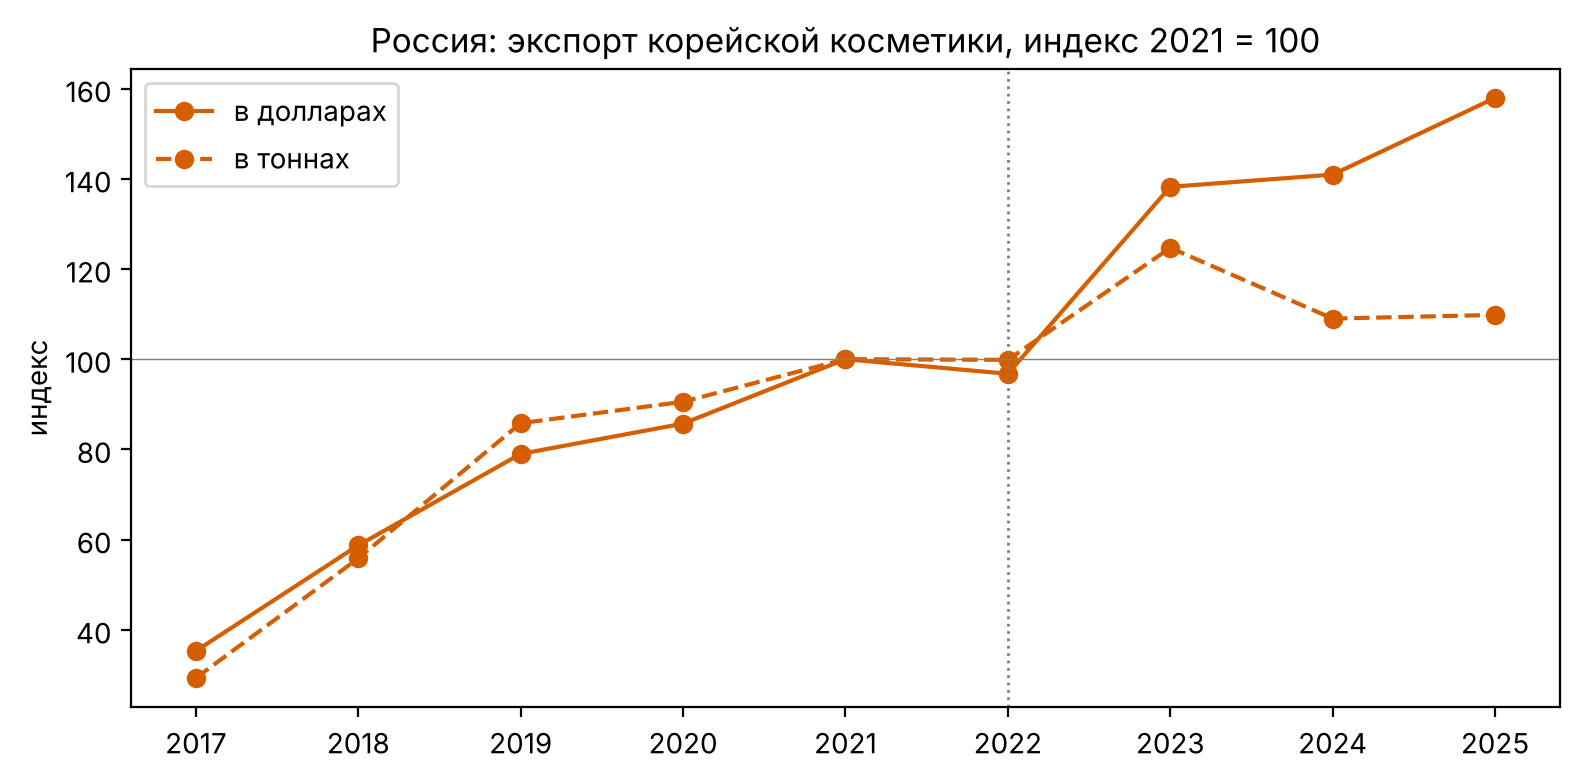

$/кг в России: {2017: 23.2, 2018: 20.3, 2019: 17.8, 2020: 18.3, 2021: 19.3, 2022: 18.7, 2023: 21.4, 2024: 25.0, 2025: 27.8}


In [12]:
ru = cc[cc['iso2'] == 'RU'].groupby('year')[['tons', 'usd_k']].sum().loc[2017:2025]
idx = ru / ru.loc[2021] * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(idx.index, idx['usd_k'], marker='o', color='#D55E00', label='в долларах')
ax.plot(idx.index, idx['tons'], marker='o', color='#D55E00', ls='--', label='в тоннах')
ax.axhline(100, color='grey', lw=.5); ax.axvline(2022, color='grey', ls=':', lw=1)
ax.set_title('Россия: экспорт корейской косметики, индекс 2021 = 100'); ax.legend(); ax.set_ylabel('индекс')
plt.tight_layout(); plt.savefig(FIG / 'q1_russia_usd_vs_tons.png', dpi=150); plt.show()
print('$/кг в России:', (ru['usd_k'] / ru['tons']).round(1).to_dict())

Рост России в долларах после 2021 года почти целиком объясняется ценой за килограмм: товар подорожал (или стал премиальнее), а объём почти не вырос.

## 2.4. Группы: Россия, другие СНГ, мир — индекс тонн

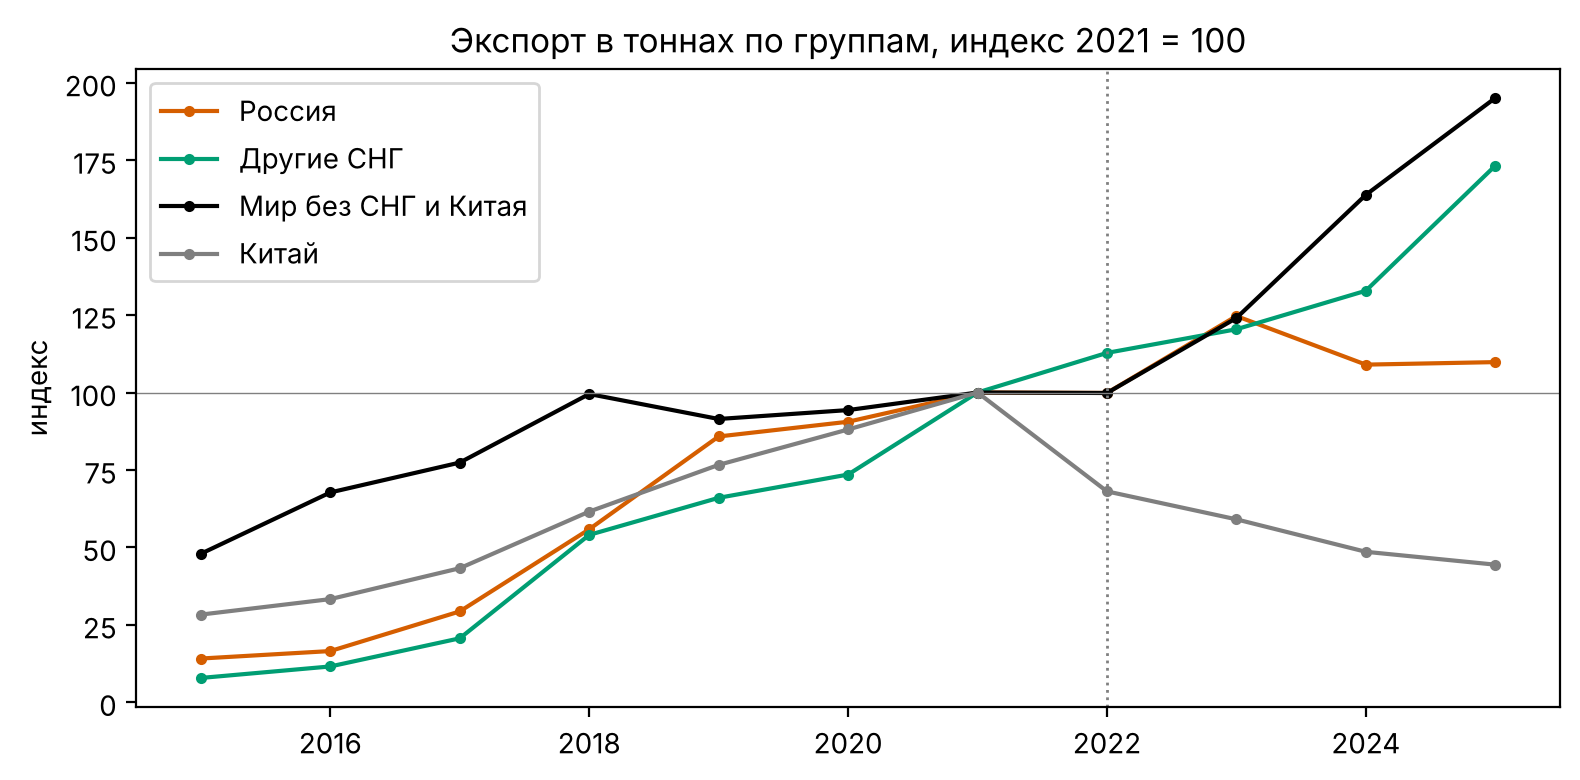

group,CN,RU,other_CIS,world_ex
month,,,,
2017,43.0,29.0,21.0,77.0
2021,100.0,100.0,100.0,100.0
2022,68.0,100.0,113.0,100.0
2023,59.0,125.0,120.0,124.0
2025,44.0,110.0,173.0,195.0


In [13]:
grp = cc[cc['group'].isin(['RU', 'other_CIS', 'world_ex', 'CN'])].groupby(['month', 'group'])['tons'].sum().unstack()
grp_y = grp.groupby(grp.index.str[:4].astype(int)).sum().loc[2015:2025]
gi = grp_y / grp_y.loc[2021] * 100
labels = {'RU': 'Россия', 'other_CIS': 'Другие СНГ', 'world_ex': 'Мир без СНГ и Китая', 'CN': 'Китай'}
colors = {'RU': '#D55E00', 'other_CIS': '#009E73', 'world_ex': '#000000', 'CN': '#7F7F7F'}
fig, ax = plt.subplots(figsize=(8, 4))
for g in ['RU', 'other_CIS', 'world_ex', 'CN']:
    ax.plot(gi.index, gi[g], marker='o', ms=3, color=colors[g], label=labels[g])
ax.axvline(2022, color='grey', ls=':', lw=1); ax.axhline(100, color='grey', lw=.5)
ax.set_title('Экспорт в тоннах по группам, индекс 2021 = 100'); ax.legend(); ax.set_ylabel('индекс')
plt.tight_layout(); plt.savefig(FIG / 'q1_groups_index_tons.png', dpi=150); plt.show()
gi.loc[[2017, 2021, 2022, 2023, 2025]].round(0)

## 2.5. t-тест: изменился ли рост после марта 2022
Сравниваем средний месячный рост год к году (в тоннах) до и после марта 2022 — отдельно для России, других СНГ и мира. Тест Уэлча (не требует равных дисперсий). Период «до» начинаем с 2017 года.

In [14]:
gy = grp.copy(); gy.index = pd.PeriodIndex(gy.index, freq='M')
yoy = (gy / gy.shift(12) - 1) * 100
rows = []
for g in ['RU', 'other_CIS', 'world_ex']:
    s = yoy[g].dropna()
    pre, post = s[(s.index >= pd.Period('2017-01', 'M')) & (s.index < pd.Period('2022-03', 'M'))], s[s.index >= pd.Period('2022-03', 'M')]
    t, p = stats.ttest_ind(pre, post, equal_var=False)
    rows.append([labels[g], pre.mean(), post.mean(), post.mean() - pre.mean(), t, p])
ttest = pd.DataFrame(rows, columns=['группа', 'рост г/г до, %', 'рост г/г после, %', 'разница, п.п.', 't', 'p-value']).round(3)
ttest

,группа,"рост г/г до, %","рост г/г после, %","разница, п.п.",t,p-value
0,Россия,52.429,7.069,-45.360,5.103,0.0
1,Другие СНГ,78.401,23.488,-54.913,3.953,0.0
2,Мир без СНГ и Китая,9.505,23.406,13.902,-3.939,0.0


**Как читать t-тест.** Рост замедлился и у России (52% → 7% в год), и у других стран СНГ (78% → 23%) — разница значима (p < 0,001). А мир без СНГ и Китая, наоборот, ускорился (10% → 23%). Важно: другие СНГ тоже замедлились, просто с более высокой базы — поэтому «санкции обрушили Россию относительно СНГ» этим тестом не доказать. Это проверим регрессией с трендами групп в разделе ML.

## 2.6. Рост × объём × цена

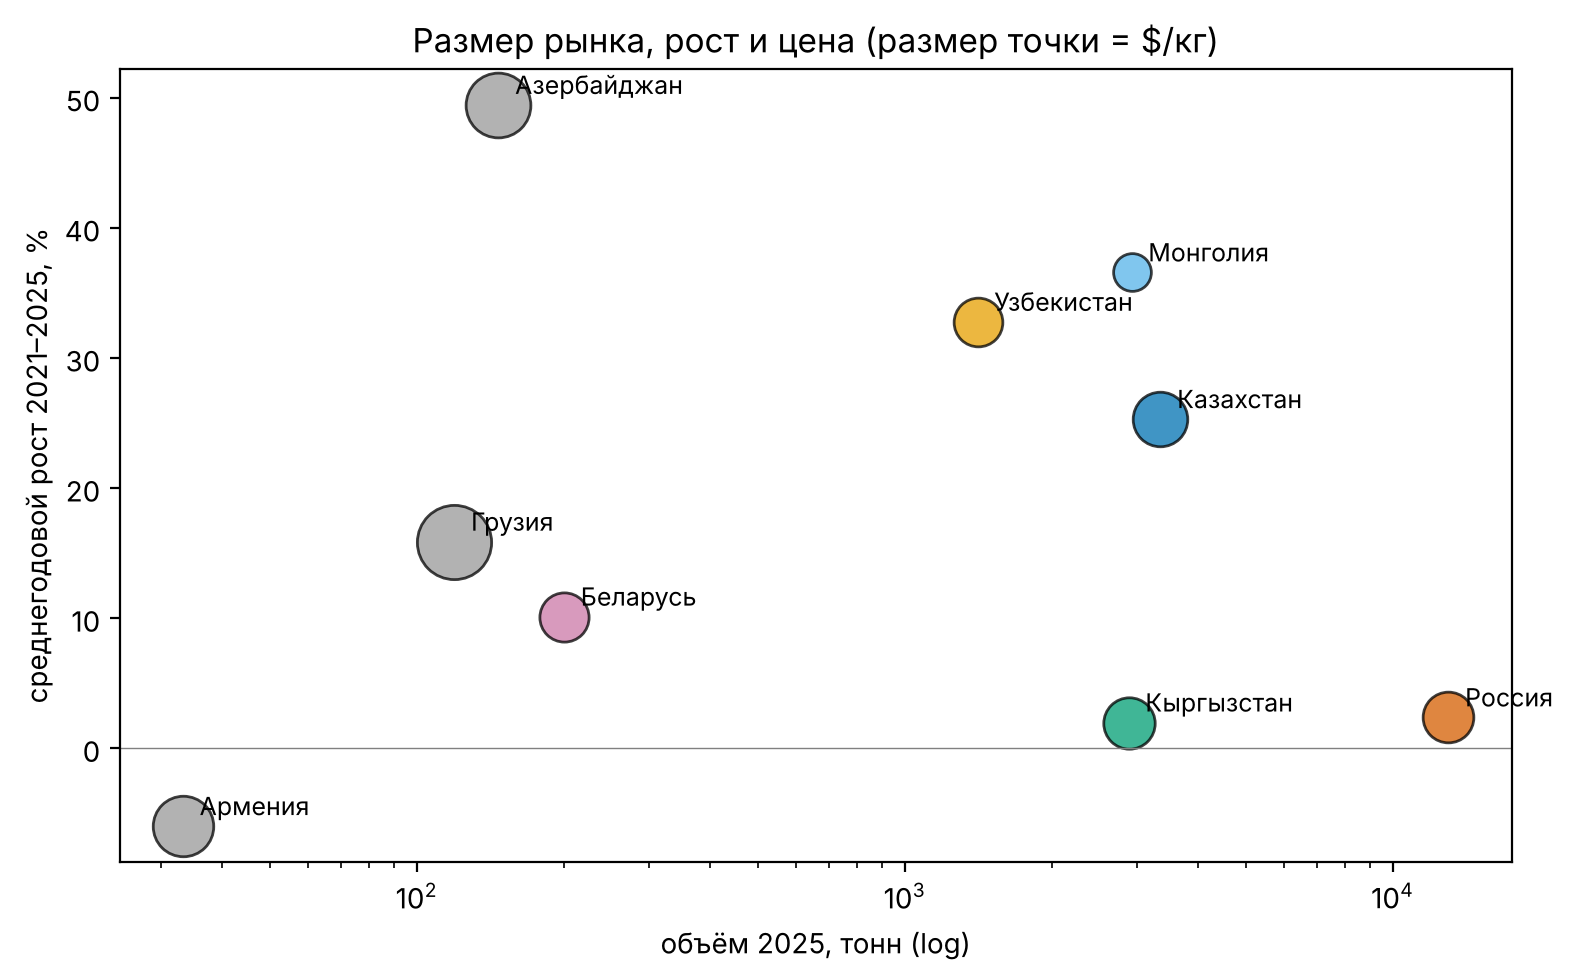

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
for i in REGION:
    r = m.loc[i]
    ax.scatter(r['тонн_2025'], r['рост_2021_25_%'], s=r['usd_за_кг'] * 12, color=PALETTE[i], alpha=.75, edgecolor='k')
    ax.annotate(r['страна'], (r['тонн_2025'], r['рост_2021_25_%']), xytext=(6, 4), textcoords='offset points', fontsize=9)
ax.set_xscale('log'); ax.axhline(0, color='grey', lw=.5)
ax.set_xlabel('объём 2025, тонн (log)'); ax.set_ylabel('среднегодовой рост 2021–2025, %')
ax.set_title('Размер рынка, рост и цена (размер точки = $/кг)')
plt.tight_layout(); plt.savefig(FIG / 'q1_growth_size_price.png', dpi=150); plt.show()

## 2.7. Насыщенность: тонн на миллион жителей

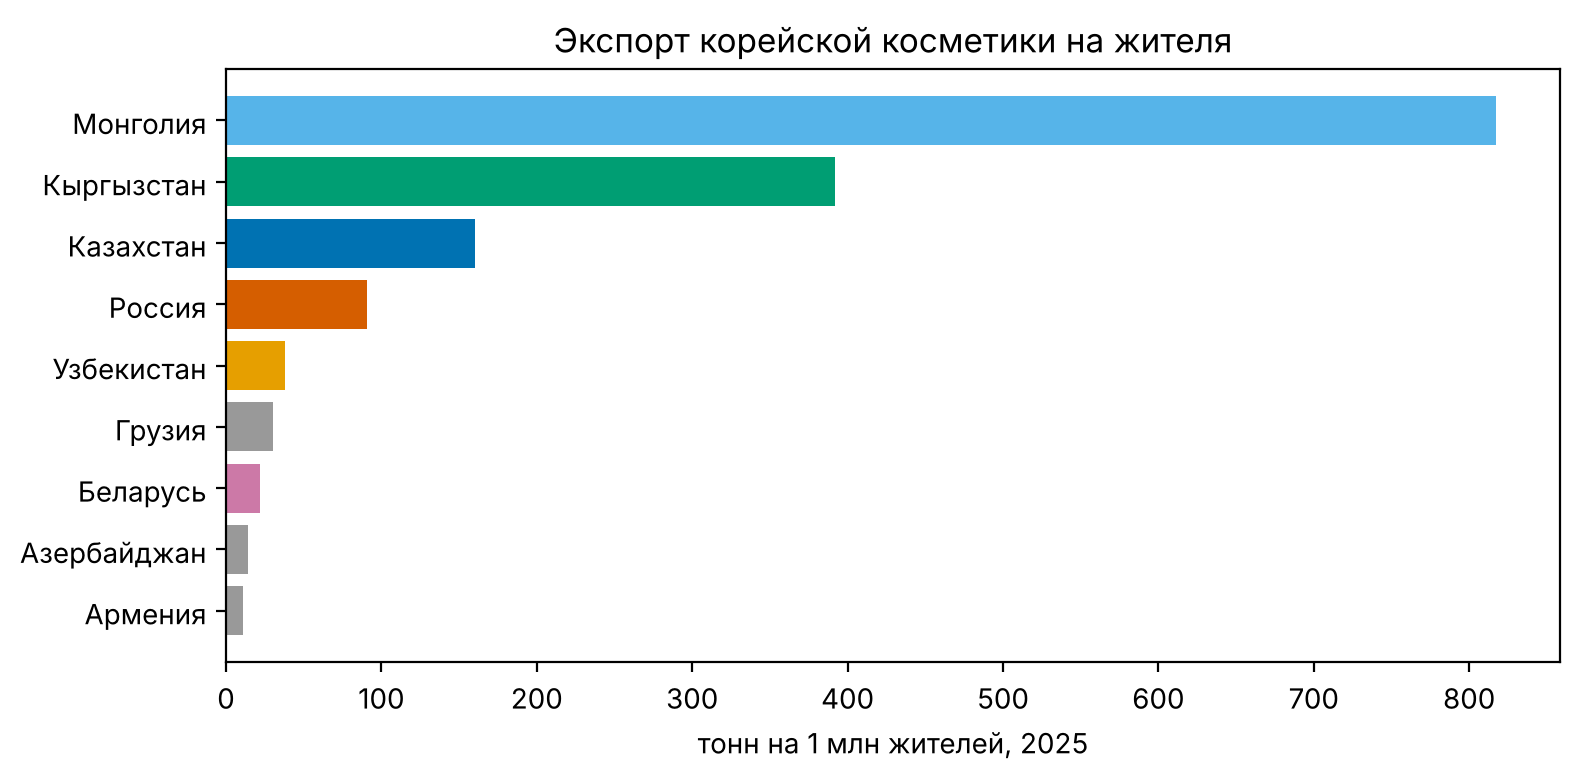

In [16]:
s = m.sort_values('тонн_на_млн_жит')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(s['страна'], s['тонн_на_млн_жит'], color=[PALETTE[i] for i in s.index])
ax.set_xlabel('тонн на 1 млн жителей, 2025'); ax.set_title('Экспорт корейской косметики на жителя')
plt.tight_layout(); plt.savefig(FIG / 'q1_per_capita.png', dpi=150); plt.show()

## 2.8. Связь метрик с экономикой (World Bank)

In [17]:
econ = wb[wb['year'] == 2024].groupby('iso3')[['gdp_pc_ppp', 'internet_pct']].first()
mm = m.join(econ, on=iso3[REGION].rename(None).reindex(m.index))
corr = mm[['тонн_2025', 'рост_2021_25_%', 'usd_за_кг', 'тонн_на_млн_жит', 'gdp_pc_ppp', 'internet_pct']].corr(method='spearman').round(2)
print('Спирмен, 9 стран (осторожно: мало точек)'); corr

Спирмен, 9 стран (осторожно: мало точек)


,тонн_2025,рост_2021_25_%,usd_за_кг,тонн_на_млн_жит,gdp_pc_ppp,internet_pct
тонн_2025,1.00,0.12,-0.55,0.80,0.27,0.68
рост_2021_25_%,0.12,1.00,-0.15,0.15,-0.05,-0.07
usd_за_кг,-0.55,-0.15,1.00,-0.53,0.23,-0.28
тонн_на_млн_жит,0.80,0.15,-0.53,1.00,-0.18,0.27
gdp_pc_ppp,0.27,-0.05,0.23,-0.18,1.00,0.53
internet_pct,0.68,-0.07,-0.28,0.27,0.53,1.00


## 2.9. Выводы EDA

1. **Россия — самый большой рынок (54% тонн региона), но объём стоит:** +2% в год в 2021–2025 против +36% в 2017–2021. Рост в долларах (+58%) — за счёт цены: $/кг 19 → 28.
2. **Растут Центральная Азия и Монголия:** Казахстан +25%, Узбекистан +33%, Монголия +37% в год. Азербайджан +49%, но с крошечной базы (147 т).
3. **Насыщенность разная в 40 раз:** Узбекистан ~38 т на млн жителей, Россия ~91, Казахстан ~160, Кыргызстан ~392, Монголия ~818. Высокие значения у небогатых Кыргызстана и Монголии — гипотеза транзита дальше (в Россию и Китай).
4. **После марта 2022 замедлились и Россия, и другие СНГ; мир ускорился.** Отдельного «удара по России» относительно СНГ t-тест не показывает — проверим регрессией.
5. **Корреляции на 9 странах слабые и ненадёжные** (Спирмен): только объём связан с долей интернета (0,68). Рейтинг строим по самим метрикам, а не по экономике.

**Предварительно для стратегии:** новому бренду (сценарий Б) интересны Казахстан (крупный и быстрорастущий) и Узбекистан (большой, ненасыщенный, быстрый рост). Бренду, который уже в России (сценарий А), — расширяться в Казахстан. Рейтинг с проверкой весов (раздел 3) это подтверждает.

# 3. ML — вопрос 1

## 3.1. Эффект 2022 года: регрессия «разность разностей» (DiD)

**Идея простыми словами.** Россия получила шок в марте 2022. Чтобы понять, сколько она «потеряла», сравниваем её с группой, которая этого шока не получила (контроль), **до и после**:
эффект = (Россия после − Россия до) − (контроль после − контроль до).

Модель (Y = log тонн в месяц, одна строка = группа × месяц, 2017-01 … 2026-10):

`log(тонны) = Россия + после_2022 + Россия × после_2022 + месяц года (+ тренды групп)`

- коэффициент при **Россия × после_2022** и есть эффект; в процентах = (e^β − 1) × 100;
- **месяц года** убирает сезонность;
- **тренды групп** — важная поправка: другие СНГ росли быстрее России и до 2022, без трендов эта разница ошибочно припишется санкциям;
- ошибки устойчивые (HC1).

Два контроля: **другие СНГ** (без Беларуси) и **мир без СНГ и Китая**.

In [18]:
import statsmodels.formula.api as smf

def did_panel(control):
    g = cc[cc['group'].isin(['RU', control])].groupby(['month', 'group'])['tons'].sum().reset_index()
    g = g[(g['month'] >= '2017-01')]
    g['ly'] = np.log(g['tons'])
    g['treat'] = (g['group'] == 'RU').astype(int)
    g['post'] = (g['month'] >= '2022-03').astype(int)
    g['t'] = pd.PeriodIndex(g['month'], freq='M').astype(int) - pd.Period('2017-01', 'M').ordinal
    g['mon'] = g['month'].str[5:]
    return g

res = []
for control in ['other_CIS', 'world_ex']:
    d = did_panel(control)
    for spec, f in [('без трендов', 'ly ~ treat * post + C(mon)'),
                    ('с трендами групп', 'ly ~ treat * post + t + treat:t + C(mon)')]:
        r = smf.ols(f, d).fit(cov_type='HC1')
        b, (lo, hi) = r.params['treat:post'], r.conf_int().loc['treat:post']
        res.append([labels[control], spec, (np.exp(b) - 1) * 100, (np.exp(lo) - 1) * 100, (np.exp(hi) - 1) * 100,
                    r.pvalues['treat:post'], r.rsquared, len(d)])
did = pd.DataFrame(res, columns=['контроль', 'модель', 'эффект, %', 'ДИ низ, %', 'ДИ верх, %', 'p-value', 'R²', 'n']).round(3)
did

,контроль,модель,"эффект, %","ДИ низ, %","ДИ верх, %",p-value,R²,n
0,Другие СНГ,без трендов,-37.529,-50.298,-21.479,0.000,0.638,236
1,Другие СНГ,с трендами групп,7.291,-20.575,44.934,0.646,0.833,236
2,Мир без СНГ и Китая,без трендов,-3.799,-18.955,14.191,0.658,0.941,236
3,Мир без СНГ и Китая,с трендами групп,-22.525,-40.980,1.702,0.066,0.966,236


## 3.2. Проверка «параллельных трендов»: эффект по годам
DiD корректен, только если до 2022 года Россия и контроль двигались похоже. Считаем разрыв «Россия − контроль» отдельно для каждого года (база — 2021). До 2022 точки должны быть около нуля без явного наклона; после — показывают эффект.

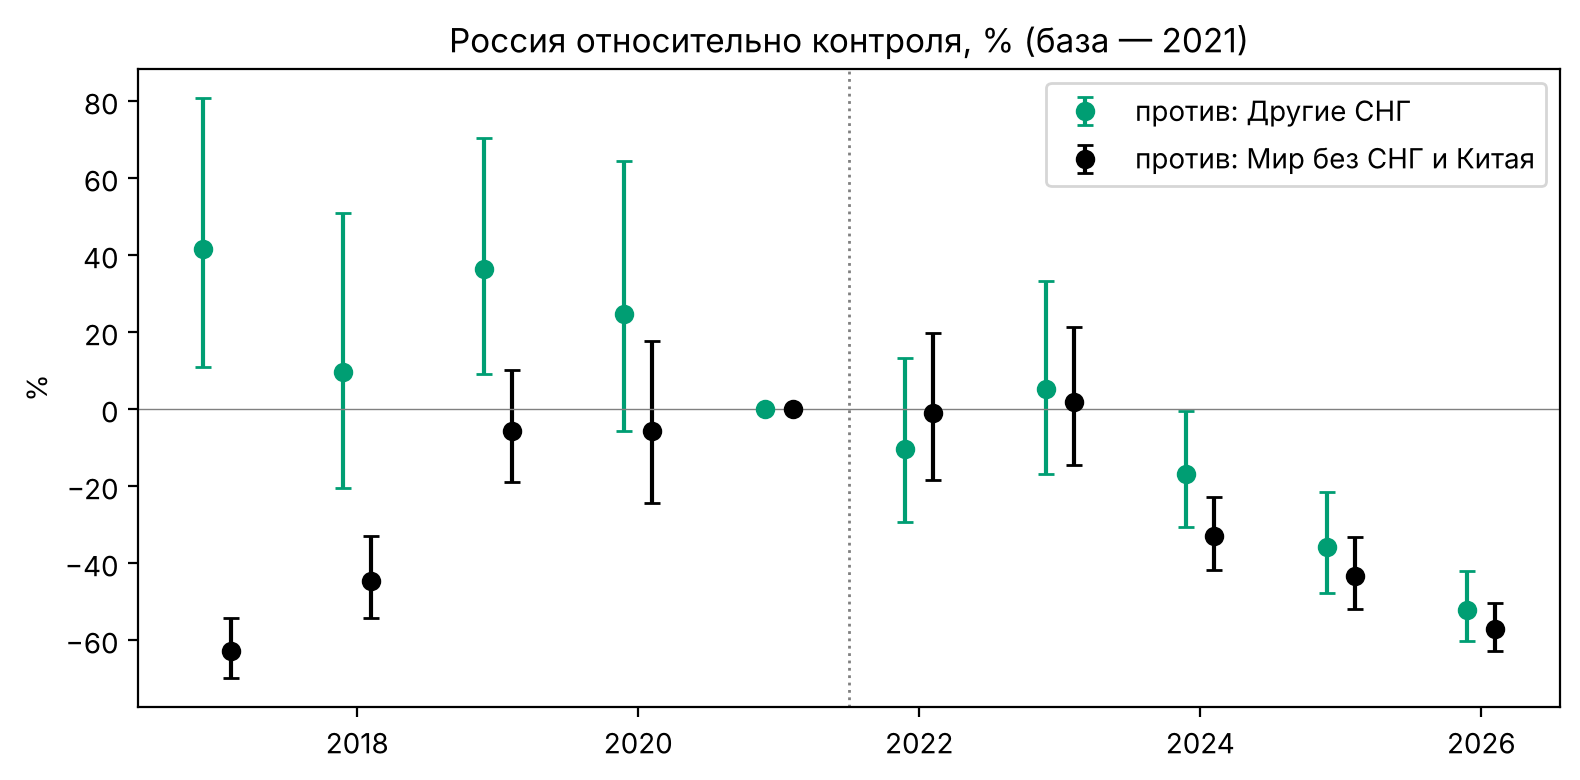

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
for control, col in [('other_CIS', '#009E73'), ('world_ex', '#000000')]:
    d = did_panel(control); d['yr'] = d['month'].str[:4]
    r = smf.ols("ly ~ treat * C(yr, Treatment('2021')) + C(mon)", d).fit(cov_type='HC1')
    keys = [k for k in r.params.index if k.startswith('treat:')]
    yrs = [int(k.split('[T.')[1][:4]) for k in keys]
    est = pd.DataFrame({'yr': yrs, 'b': r.params[keys].values, 'lo': r.conf_int().loc[keys, 0].values,
                        'hi': r.conf_int().loc[keys, 1].values})
    est = pd.concat([est, pd.DataFrame({'yr': [2021], 'b': [0], 'lo': [0], 'hi': [0]})]).sort_values('yr')
    pct = (np.exp(est[['b', 'lo', 'hi']]) - 1) * 100
    ax.errorbar(est['yr'] + (0.1 if control == 'world_ex' else -0.1), pct['b'],
                yerr=[pct['b'] - pct['lo'], pct['hi'] - pct['b']], fmt='o', color=col, capsize=3, label='против: ' + labels[control])
ax.axhline(0, color='grey', lw=.5); ax.axvline(2021.5, color='grey', ls=':', lw=1)
ax.set_title('Россия относительно контроля, % (база — 2021)'); ax.set_ylabel('%'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'q1_event_study.png', dpi=150); plt.show()

**Как читать.** (1) **До 2022 тренды не параллельны:** относительно мира Россия догоняла (с −63% в 2017 до 0 в 2021), относительно других СНГ — отставала (с +42% до 0). Значит, простая DiD «без трендов» некорректна, правильная — **с трендами групп** (таблица 3.1). (2) **Разрыв открывается не в 2022, а с 2024:** в 2022–2023 точки около нуля, в 2024–2026 — −17…−52% к СНГ и −33…−57% к миру. Гипотеза: дело не в самом шоке марта 2022, а в более поздних факторах — платежи и логистика, конкуренция китайской косметики, подготовка к маркировке «Честный знак».

## 3.3. Проверка: тренд России до 2022, продолженный вперёд
Учим простую регрессию log(тонны) ~ тренд + месяц года **только на 2017-01 … 2022-02** и продолжаем её на 2022–2026. Разница «факт − прогноз» показывает, где была бы Россия без шока, если бы рост шёл как раньше.

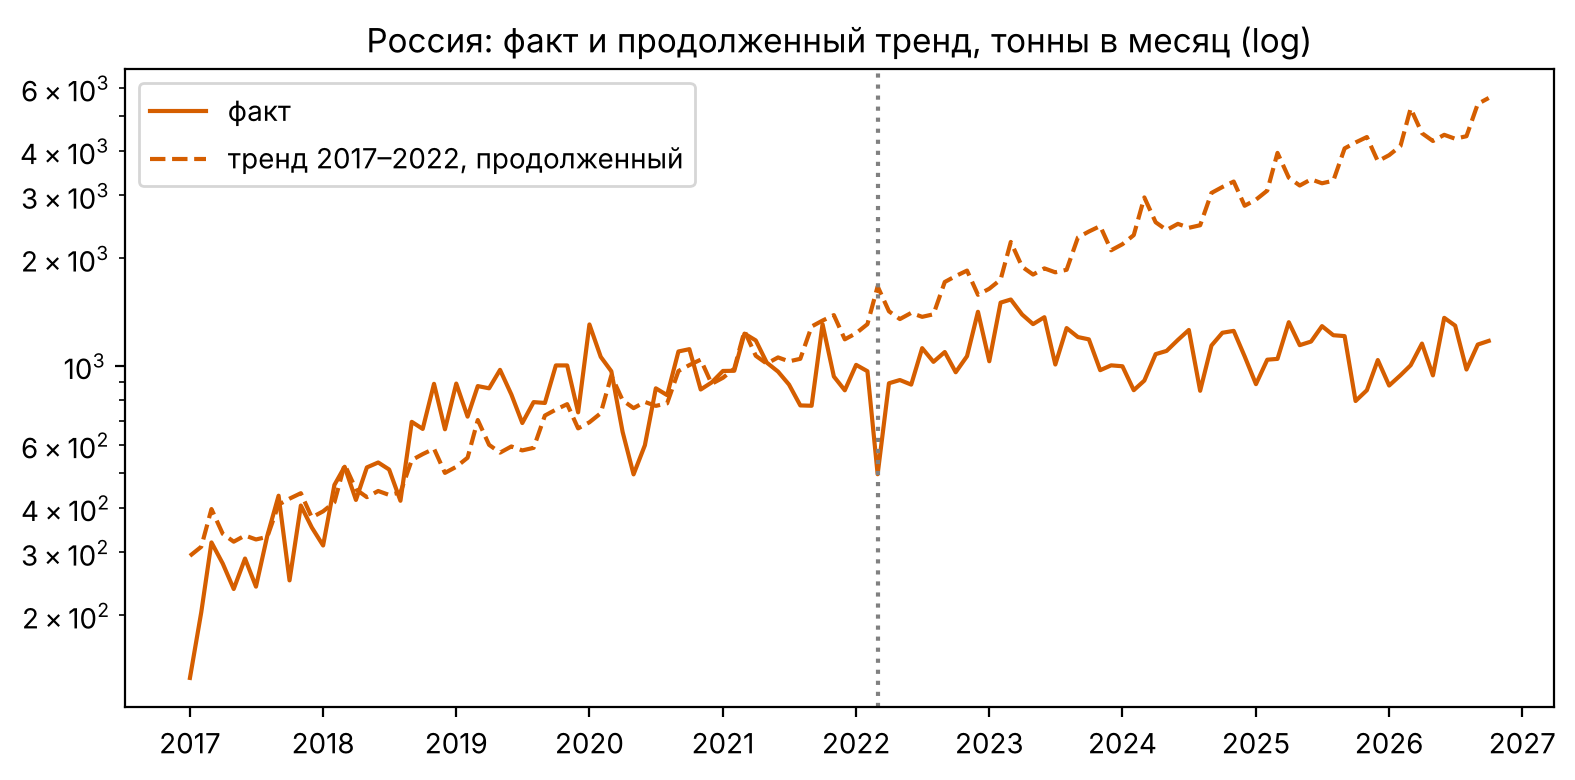

2025: факт 13011 т, прогноз по старому тренду 42781 т, факт/прогноз = 0.30


In [20]:
ru_m = cc[cc['iso2'] == 'RU'][['month', 'tons']].copy()
ru_m = ru_m[ru_m['month'] >= '2017-01']
ru_m['t'] = np.arange(len(ru_m)); ru_m['mon'] = ru_m['month'].str[5:]; ru_m['ly'] = np.log(ru_m['tons'])
pre = ru_m[ru_m['month'] < '2022-03']
r_pre = smf.ols('ly ~ t + C(mon)', pre).fit()
ru_m['pred'] = np.exp(r_pre.predict(ru_m))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pd.to_datetime(ru_m['month']), ru_m['tons'], color='#D55E00', label='факт')
ax.plot(pd.to_datetime(ru_m['month']), ru_m['pred'], color='#D55E00', ls='--', label='тренд 2017–2022, продолженный')
ax.axvline(pd.Timestamp('2022-03-01'), color='grey', ls=':')
ax.set_yscale('log'); ax.set_title('Россия: факт и продолженный тренд, тонны в месяц (log)'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'q1_ru_counterfactual.png', dpi=150); plt.show()
post_ = ru_m[ru_m['month'] >= '2022-03']
print('2025: факт %.0f т, прогноз по старому тренду %.0f т, факт/прогноз = %.2f' % (
    post_[post_['month'].str[:4] == '2025']['tons'].sum(), post_[post_['month'].str[:4] == '2025']['pred'].sum(),
    post_[post_['month'].str[:4] == '2025']['tons'].sum() / post_[post_['month'].str[:4] == '2025']['pred'].sum()))

## 3.4. Рейтинг стран

Сводим 5 метрик из раздела 2 в одну оценку. Каждую метрику переводим в z-оценку (сколько стандартных отклонений от среднего), задаём направление «что хорошо для бренда»:

| Метрика | Направление | Почему |
|---|---|---|
| объём 2025 (log) | + | больше рынок — больше продаж |
| рост 2021–2025 | + | рынок, который растёт |
| нестабильность (CV) | − | непредсказуемый рынок — риск |
| $/кг | + | готовность платить, проще зайти с премиальным продуктом |
| тонн на млн жителей | − | ниже насыщенность — больше места для нового бренда |

Базовые веса равные (по 0,2). Отдельно для сценариев: **Б (новый бренд)** — все 9 стран; **А (бренд уже в России)** — без России, куда расширяться.

In [21]:
DIRS = {'тонн_2025': 1, 'рост_2021_25_%': 1, 'нестабильность_CV': -1, 'usd_за_кг': 1, 'тонн_на_млн_жит': -1}
X = m[list(DIRS)].copy(); X['тонн_2025'] = np.log(X['тонн_2025'])
Z = (X - X.mean()) / X.std()
Z = Z * pd.Series(DIRS)
w0 = np.full(5, 0.2)
rank = m[['страна']].copy(); rank['оценка'] = Z.values @ w0
rank = rank.sort_values('оценка', ascending=False); rank['место'] = range(1, len(rank) + 1)
rank.round(2)

,страна,оценка,место
AZ,Азербайджан,0.53,1
KZ,Казахстан,0.32,2
UZ,Узбекистан,0.30,3
RU,Россия,0.27,4
GE,Грузия,0.13,5
KG,Кыргызстан,-0.10,6
MN,Монголия,-0.28,7
BY,Беларусь,-0.51,8
AM,Армения,-0.67,9


## 3.5. Проверка устойчивости: 1000 случайных наборов весов
Веса — субъективный выбор. Проверяем: если 1000 раз случайно поменять веса (каждый раз они в сумме = 1), как часто страна попадает в топ-3 и на 1-е место? Если лидер остаётся лидером почти при любых весах — вывод надёжный.

In [22]:
rng = np.random.default_rng(42)
W = rng.dirichlet(np.ones(5), 1000)
def robustness(Zs):
    S = Zs.values @ W.T                        # страны × 1000 вариантов
    ranks = (-S).argsort(0).argsort(0) + 1
    return pd.DataFrame({'страна': [name[i] for i in Zs.index],
                         'топ-1, %': (ranks == 1).mean(1) * 100,
                         'топ-3, %': (ranks <= 3).mean(1) * 100,
                         'среднее место': ranks.mean(1)}, index=Zs.index).sort_values('среднее место')
rob_B = robustness(Z)
Z_A = Z.drop('RU'); Z_A = (Z_A - Z_A.mean()) / Z_A.std()   # без России пересчитываем z
rob_A = robustness(Z_A)
print('Сценарий Б — новый бренд, все 9 стран'); display(rob_B.round(1))
print('Сценарий А — бренд уже в России: куда расширяться'); display(rob_A.round(1))

Сценарий Б — новый бренд, все 9 стран


,страна,"топ-1, %","топ-3, %",среднее место
AZ,Азербайджан,51.3,73.3,2.3
KZ,Казахстан,1.3,69.1,3.1
RU,Россия,31.2,45.8,3.4
UZ,Узбекистан,1.2,55.2,3.4
GE,Грузия,13.7,35.0,4.5
KG,Кыргызстан,0.0,9.0,6.1
MN,Монголия,1.3,9.0,6.6
BY,Беларусь,0.0,0.0,7.6
AM,Армения,0.0,3.6,8.0


Сценарий А — бренд уже в России: куда расширяться


,страна,"топ-1, %","топ-3, %",среднее место
AZ,Азербайджан,51.7,80.3,2.1
KZ,Казахстан,24.0,81.1,2.6
UZ,Узбекистан,6.6,69.3,2.9
GE,Грузия,12.7,34.3,4.0
KG,Кыргызстан,2.8,16.9,5.0
MN,Монголия,2.2,14.9,5.6
BY,Беларусь,0.0,0.0,6.6
AM,Армения,0.0,3.2,7.2


**Чувствительность к отдельным метрикам:** что будет, если убрать одну метрику (её вес = 0, остальные равные).

In [23]:
sens = {}
for k in DIRS:
    w = np.array([0 if c == k else 0.25 for c in DIRS])
    sens['без: ' + k] = pd.Series(Z.values @ w, index=Z.index).rank(ascending=False).astype(int)
sens = pd.DataFrame(sens); sens.insert(0, 'базовое место', rank['место']); sens.index = [name[i] for i in sens.index]
sens.sort_values('базовое место')

,базовое место,без: тонн_2025,без: рост_2021_25_%,без: нестабильность_CV,без: usd_за_кг,без: тонн_на_млн_жит
Азербайджан,1,1,3,1,3,1
Казахстан,2,4,2,3,4,2
Узбекистан,3,3,5,4,1,5
Россия,4,5,1,5,2,3
Грузия,5,2,4,2,7,7
Кыргызстан,6,6,6,7,6,6
Монголия,7,9,9,9,5,4
Беларусь,8,8,8,6,8,8
Армения,9,7,7,8,9,9


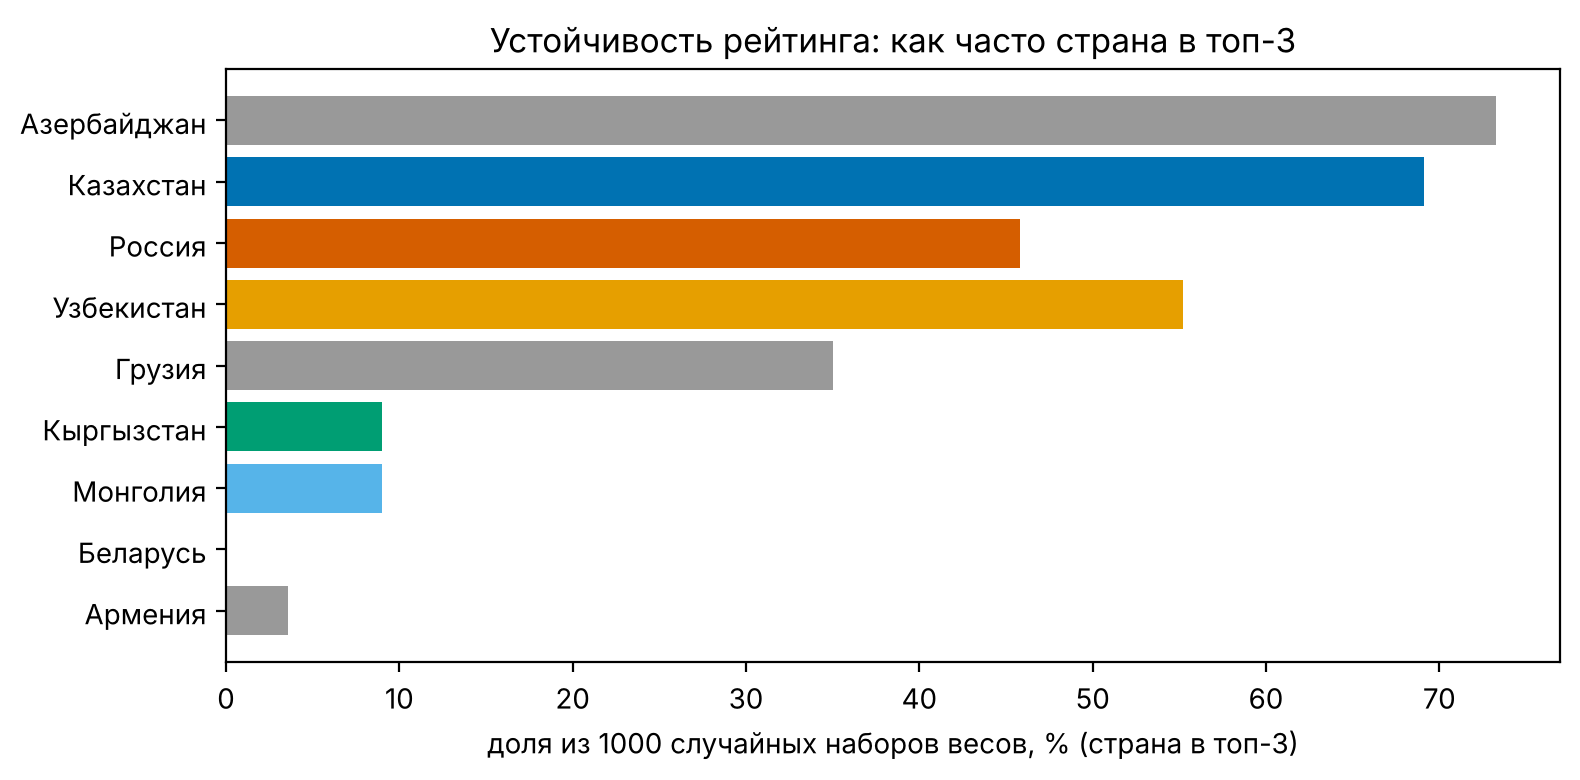

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
r = rob_B.iloc[::-1]
ax.barh(r['страна'], r['топ-3, %'], color=[PALETTE[i] for i in r.index])
ax.set_xlabel('доля из 1000 случайных наборов весов, % (страна в топ-3)')
ax.set_title('Устойчивость рейтинга: как часто страна в топ-3')
plt.tight_layout(); plt.savefig(FIG / 'q1_rating_robustness.png', dpi=150); plt.show()

## 3.6. Бизнес-правило: минимальный размер рынка
Азербайджан на 1-м месте из-за высокого роста и цены, но его рынок — 147 т в год, в 90 раз меньше России. Рост с маленькой базы шумный, а бренду для выхода нужен дистрибьютор и объём продаж. Поэтому для рекомендации добавляем правило: **рассматриваем рынки от 1 000 т в год** (порог круглый и задан из бизнес-логики, а не подобран под результат). Маленькие рынки остаются в отчёте как «наблюдать».

In [25]:
BIG = m.index[m['тонн_2025'] >= 1000]
def zscore(idx):
    Xs = X.loc[idx]; Zs = (Xs - Xs.mean()) / Xs.std(); return Zs * pd.Series(DIRS)
print('Рынки ≥ 1 000 т:', [name[i] for i in BIG])
rob_B_big = robustness(zscore(BIG))
rob_A_big = robustness(zscore(BIG.drop('RU')))
print('Сценарий Б — новый бренд'); display(rob_B_big.round(1))
print('Сценарий А — бренд уже в России: куда расширяться'); display(rob_A_big.round(1))

Рынки ≥ 1 000 т: ['Россия', 'Казахстан', 'Кыргызстан', 'Узбекистан', 'Монголия']
Сценарий Б — новый бренд


,страна,"топ-1, %","топ-3, %",среднее место
RU,Россия,72.1,94.4,1.5
KZ,Казахстан,17.8,92.2,2.2
KG,Кыргызстан,0.1,53.8,3.4
UZ,Узбекистан,6.4,39.7,3.6
MN,Монголия,3.6,19.9,4.3


Сценарий А — бренд уже в России: куда расширяться


,страна,"топ-1, %","топ-3, %",среднее место
KZ,Казахстан,63.9,99.9,1.5
KG,Кыргызстан,22.7,84.1,2.4
UZ,Узбекистан,5.6,60.8,3.1
MN,Монголия,7.8,55.2,3.1


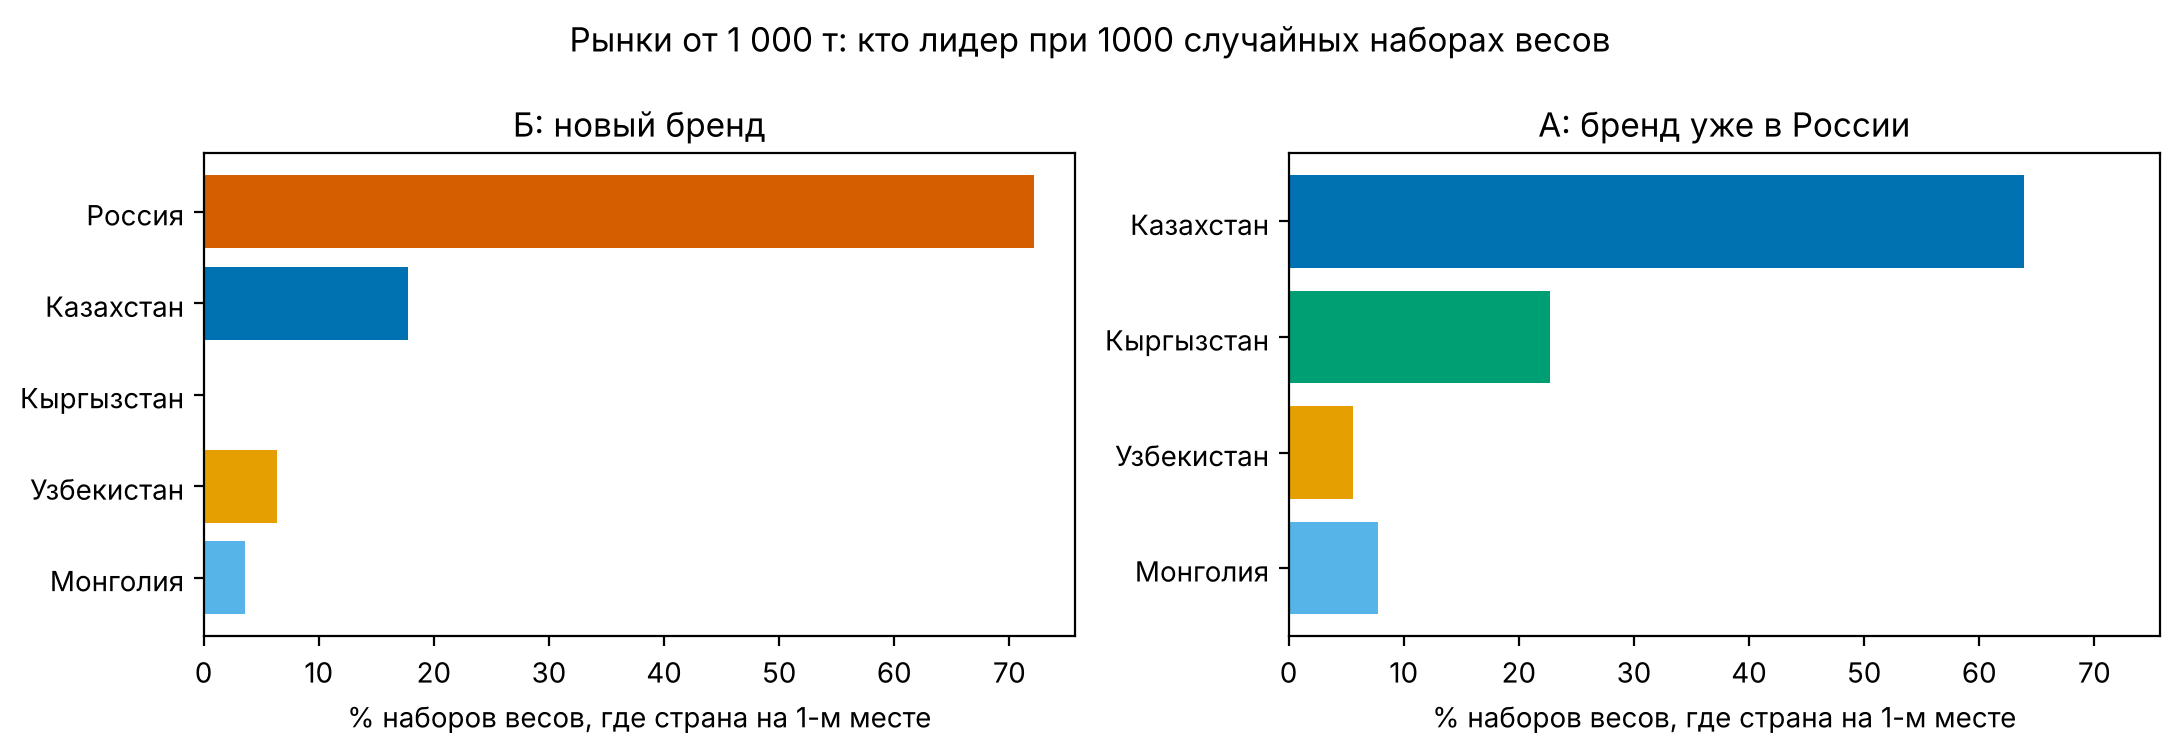

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for a, (t, r) in zip(ax, [('Б: новый бренд', rob_B_big), ('А: бренд уже в России', rob_A_big)]):
    r = r.iloc[::-1]
    a.barh(r['страна'], r['топ-1, %'], color=[PALETTE[i] for i in r.index])
    a.set_title(t); a.set_xlabel('% наборов весов, где страна на 1-м месте')
fig.suptitle('Рынки от 1 000 т: кто лидер при 1000 случайных наборах весов')
plt.tight_layout(); plt.savefig(FIG / 'q1_rating_big_markets.png', dpi=150); plt.show()

## 3.7. Выводы по вопросу 1

**Эффект 2022 (тонны).**
- С поправкой на тренды: относительно других СНГ отдельного эффекта нет (+7%, p = 0,65); относительно мира без СНГ и Китая −23% (p = 0,07, на грани значимости), а без ковидного 2020 года — −13%, незначимо (3.8). То есть **отдельного «эффекта марта 2022» данные надёжно не показывают**.
- Разрыв России с контролем открывается **с 2024 года**, а не в марте 2022. Если бы Россия росла как в 2017–2022, в 2025 было бы ~43 тыс. т вместо 13 тыс. т — но этот прогноз продлевает очень быстрый рост 2017–2021 и сильно завышен; честно говорить «объём остановился», а не «потеряли 70%».

**Куда идти.**
- Среди всех 9 стран лидирует Азербайджан, но это эффект маленькой базы (147 т) → «наблюдать».
- **Сценарий Б (новый бренд), рынки от 1 000 т:** Россия — 1-е место в 72% наборов весов (самый большой и стабильный рынок, высокая цена за кг), Казахстан — в топ-2 почти всегда (топ-3 в 92%). Россия — для премиального продукта, Казахстан — для роста объёма.
- **Сценарий А (бренд уже в России):** **Казахстан** — 1-е место в 64% наборов, топ-3 в 99,9%: крупный, быстрорастущий (+25% в год), с высокой ценой за кг. Второй — Кыргызстан (84% в топ-3), но осторожно: рост +2% в год и подозрение на транзит.
- Узбекистан — «ставка на будущее»: самый ненасыщенный (38 т на млн жителей) и быстрорастущий (+33%), но пока небольшой.

**Что делать бренду:** «Новому бренду: если продукт премиальный — начинать с России, если ставка на объём и рост — с Казахстана. Бренду, который уже в России, расширяться в Казахстан, следующим шагом — Узбекистан. Россия остаётся крупнейшим рынком, но растёт только в деньгах, не в тоннах.»

## 3.8. Проверки устойчивости вопроса 1

**(а) Без 2020 года.** 2020 — ковидный год с перебоями в логистике. Пересчитываем эффект 2022 без 2020 года: если результат сохраняется, ковид его не определяет.

**(б) Рост после шока.** В рейтинге рост считается за 2021–2025. Проверяем вариант «рост 2022–2025» — только период после шока.

**(в) Интерес к брендам как 6-я метрика.** В ТЗ указан файл 02 (интерес к корейским брендам). Шкалы источников разные (Россия — Вордстат, остальные — Google Trends), поэтому сравниваем только **рост** интереса 2025 к 2021, а не уровни. Метрика есть для 5 стран (Россия, Казахстан, Кыргызстан, Узбекистан, Беларусь), Medicube исключён (его взрывной рост искажает сумму брендов).

In [27]:
rows = []
for control in ['other_CIS', 'world_ex']:
    d = did_panel(control); d = d[d['month'].str[:4] != '2020']
    r = smf.ols('ly ~ treat * post + t + treat:t + C(mon)', d).fit(cov_type='HC1')
    b = r.params['treat:post']
    rows.append([labels[control], (np.exp(b) - 1) * 100, r.pvalues['treat:post']])
did_no2020 = pd.DataFrame(rows, columns=['контроль', 'эффект без 2020, %', 'p-value']).round(3)
did_no2020['эффект с 2020, %'] = did[did['модель'] == 'с трендами групп']['эффект, %'].values
did_no2020

,контроль,"эффект без 2020, %",p-value,"эффект с 2020, %"
0,Другие СНГ,14.211,0.397,7.291
1,Мир без СНГ и Китая,-12.634,0.364,-22.525


In [28]:
m2 = m.copy(); m2['рост_2022_25_%'] = [cagr(ann.loc[i], 2022, 2025) * 100 for i in REGION]
DIRS2 = {'тонн_2025': 1, 'рост_2022_25_%': 1, 'нестабильность_CV': -1, 'usd_за_кг': 1, 'тонн_на_млн_жит': -1}
X2 = m2[list(DIRS2)].copy(); X2['тонн_2025'] = np.log(X2['тонн_2025'])
Zb = ((X2.loc[BIG] - X2.loc[BIG].mean()) / X2.loc[BIG].std()) * pd.Series(DIRS2)
cmp_ = pd.DataFrame({'рост 2021–25: топ-1, %': rob_B_big['топ-1, %'], 'рост 2022–25: топ-1, %': robustness(Zb)['топ-1, %'],
                     'рост 2021–25: топ-3, %': rob_B_big['топ-3, %'], 'рост 2022–25: топ-3, %': robustness(Zb)['топ-3, %']})
cmp_.index = [name[i] for i in cmp_.index]
print('Сценарий Б, рынки ≥ 1 000 т: меняется ли лидер, если рост считать только после шока')
cmp_.round(1)

Сценарий Б, рынки ≥ 1 000 т: меняется ли лидер, если рост считать только после шока


,"рост 2021–25: топ-1, %","рост 2022–25: топ-1, %","рост 2021–25: топ-3, %","рост 2022–25: топ-3, %"
Кыргызстан,0.1,0.1,53.8,50.4
Казахстан,17.8,17.2,92.2,93.9
Монголия,3.6,0.0,19.9,10.1
Россия,72.1,71.1,94.4,97.4
Узбекистан,6.4,11.6,39.7,48.2


In [29]:
sc = pd.read_csv(CLEAN / 'search_clean.csv', encoding='utf-8-sig')
br_tr = sc[sc['export_id'] == 'without_medicube'].groupby(['geo', sc['month'].str[:4]])['value'].sum().unstack()
br_ru = sc[(sc['export_id'] == 'ws') & (sc['group'] == 'brand') & (~sc['term'].isin(['medicube']))]
br_ru = br_ru.groupby(br_ru['month'].str[:4])['value'].sum().rename('RU').to_frame().T
brands = pd.concat([br_tr, br_ru])
m['рост_интереса_к_брендам_x'] = (brands['2025'] / brands['2021']).reindex(m.index)
print('Рост интереса к корейским брендам 2025 / 2021 (раз):')
display(m[['страна', 'рост_интереса_к_брендам_x']].dropna().round(2))
HAS = m.index[m['рост_интереса_к_брендам_x'].notna()]
DIRS6 = DIRS | {'рост_интереса_к_брендам_x': 1}
X6 = m.loc[HAS, list(DIRS6)].copy(); X6['тонн_2025'] = np.log(X6['тонн_2025'])
Z6 = ((X6 - X6.mean()) / X6.std()) * pd.Series(DIRS6)
W6 = rng.dirichlet(np.ones(6), 1000)
S6 = Z6.values @ W6.T; rk6 = (-S6).argsort(0).argsort(0) + 1
Z5 = ((X6[list(DIRS)] - X6[list(DIRS)].mean()) / X6[list(DIRS)].std()) * pd.Series(DIRS)
r5_ = robustness(Z5)
cmp6 = pd.DataFrame({'5 метрик: топ-1, %': r5_['топ-1, %'], '6 метрик: топ-1, %': pd.Series((rk6 == 1).mean(1) * 100, index=HAS),
                     '5 метрик: среднее место': r5_['среднее место'], '6 метрик: среднее место': pd.Series(rk6.mean(1), index=HAS)})
cmp6.index = [name[i] for i in cmp6.index]
print('Те же 5 стран: рейтинг без и с интересом к брендам')
cmp6.sort_values('6 метрик: среднее место').round(1)

Рост интереса к корейским брендам 2025 / 2021 (раз):


,страна,рост_интереса_к_брендам_x
RU,Россия,1.17
KZ,Казахстан,3.44
KG,Кыргызстан,8.61
UZ,Узбекистан,5.46
BY,Беларусь,2.17


Те же 5 стран: рейтинг без и с интересом к брендам


,"5 метрик: топ-1, %","6 метрик: топ-1, %",5 метрик: среднее место,6 метрик: среднее место
Казахстан,57.3,46.9,1.5,1.7
Узбекистан,21.5,29.5,2.5,2.4
Россия,21.2,11.9,2.2,2.9
Кыргызстан,0.0,11.7,4.0,3.2
Беларусь,0.0,0.0,4.7,4.8


**Итог проверок 3.8.**
- **(а) Без 2020 года** эффект 2022 относительно мира −13% (p = 0,36), относительно других СНГ +14% (p = 0,40) — оба незначимы. Значит, оценка «−23% к миру» неустойчива и частично держится на ковидном 2020 году. Надёжный вывод вопроса 1 — не «санкции марта 2022 обрушили Россию», а «**объём России остановился, а разрыв с соседями и миром открылся с 2024 года**» (раздел 3.2).
- **(б) Рост только после шока (2022–2025)** рейтинг не меняет: Россия — 1-е место в 71% наборов весов (было 72%), Казахстан в топ-3 в 94% (было 92%). Вывод «куда идти» устойчив.
- **(в) С интересом к брендам** (6-я метрика) **Казахстан остаётся лидером** среди 5 стран (1-е место в 47% наборов, среднее место 1,7). Узбекистан поднимается (интерес к корейским брендам вырос в 5,5 раза), Россия опускается (рост в 1,2 раза). Оговорка: у России Вордстат, у остальных Google Trends с маленькой базы, поэтому кратный рост в Центральной Азии частично — эффект низкого старта.

# 4. Вопрос 5а: когда Корея отгружает больше всего (сезонность отгрузок)

**Вопрос:** в какие месяцы года отгрузки в каждую страну выше обычного, а в какие ниже? От этого зависит, когда отправлять товар к запуску.

**Данные:** тонны по месяцам, 2017-01 … 2026-10, пять крупных рынков (Россия, Казахстан, Кыргызстан, Узбекистан, Монголия). Маленькие рынки слишком шумные для помесячного анализа. 2015–2016 не берём: базы у Центральной Азии ещё крошечные.

**Как убираем тренд.** Рынки растут, поэтому поздние месяцы «выглядят» сильнее просто из-за роста. Сезонный индекс = тонны месяца ÷ центрированное скользящее среднее за 12 месяцев. Индекс 1,2 значит «на 20% выше обычного для этого времени». Центрированное среднее здесь допустимо: это описание прошлого, а не признак для прогноза.

In [30]:
SEAS = ['RU', 'KZ', 'KG', 'UZ', 'MN']
MONTHS_RU = ['янв', 'фев', 'мар', 'апр', 'май', 'июн', 'июл', 'авг', 'сен', 'окт', 'ноя', 'дек']
SEOLLAL = {2015: 2, 2016: 2, 2017: 1, 2018: 2, 2019: 2, 2020: 1, 2021: 2, 2022: 2, 2023: 1, 2024: 2, 2025: 1, 2026: 2}
CHUSEOK = {y: (10 if y in (2017, 2020, 2025) else 9) for y in range(2015, 2027)}

s5 = cc[cc['iso2'].isin(SEAS) & (cc['month'] >= '2016-07')].pivot_table(index='month', columns='iso2', values='tons')[SEAS]
ma = s5.rolling(12, center=True).mean()
ma = (ma + ma.shift(-1)) / 2                       # 2×12 центрированное среднее (стандарт для чётного окна)
si = (s5 / ma)
si = si[(si.index >= '2017-01')].dropna(how='all')
si_long = si.reset_index().melt('month', var_name='iso2', value_name='si').dropna()
si_long['m'] = si_long['month'].str[5:].astype(int); si_long['y'] = si_long['month'].str[:4].astype(int)
profile = si_long.groupby(['iso2', 'm'])['si'].mean().unstack().reindex(SEAS)
profile.columns = MONTHS_RU
profile.index = [name[i] for i in profile.index]
profile.round(2)

,янв,фев,мар,апр,май,июн,июл,авг,сен,окт,ноя,дек
Россия,0.96,1.00,1.04,1.03,0.97,0.98,0.97,0.93,1.06,1.03,1.02,0.95
Казахстан,0.83,0.93,0.94,1.04,1.04,0.93,1.01,1.15,1.11,1.00,1.18,0.77
Кыргызстан,0.91,0.93,1.26,0.98,0.91,0.95,0.82,0.91,1.10,1.20,1.11,0.87
Узбекистан,0.88,0.96,0.98,1.20,0.81,0.84,1.20,0.83,1.22,0.84,1.03,1.01
Монголия,0.82,0.65,1.03,1.09,1.16,1.08,1.19,1.11,1.21,1.00,0.84,0.74


## 4.1. Тепловая карта: страна × месяц

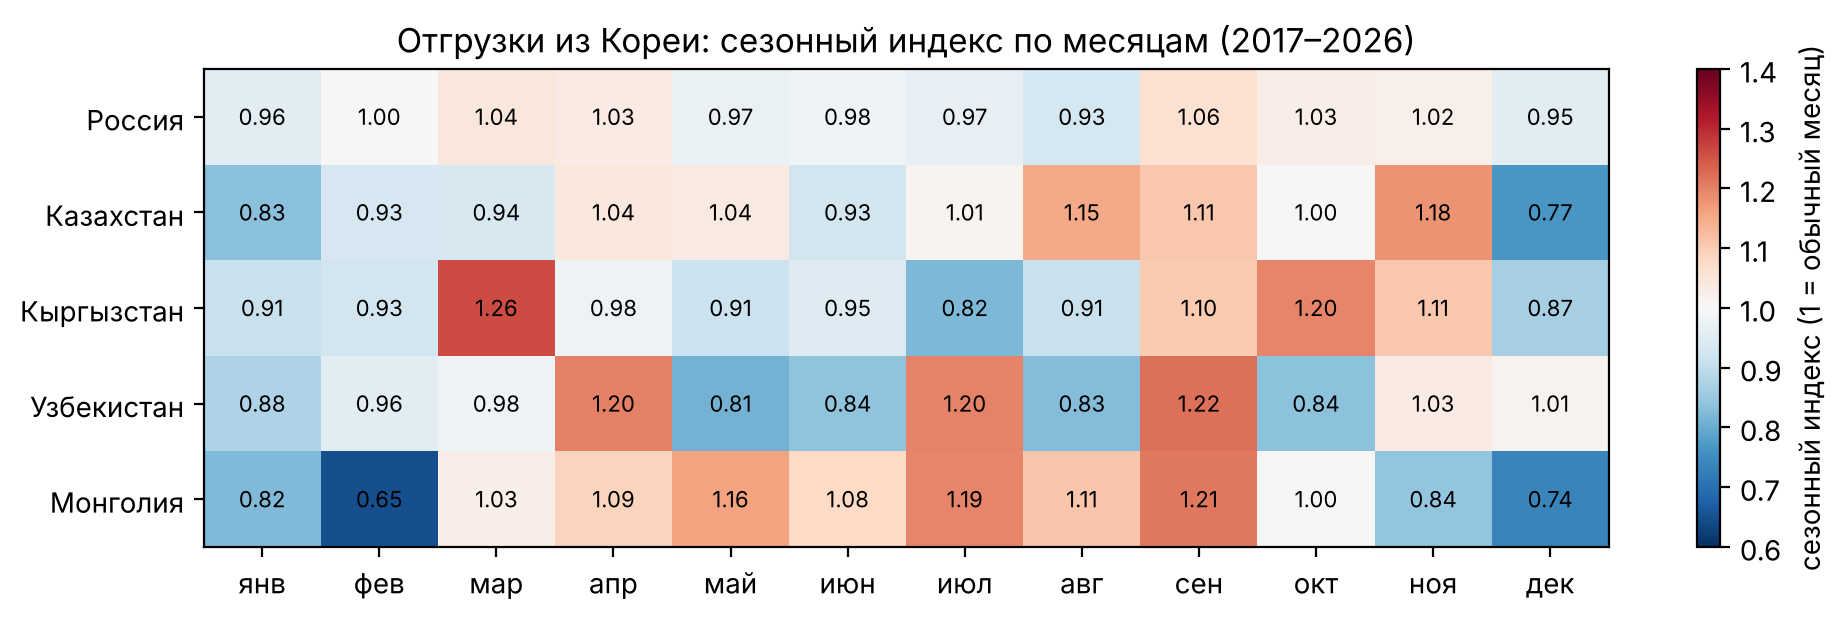

In [31]:
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(profile.values, cmap='RdBu_r', vmin=0.6, vmax=1.4, aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS_RU); ax.set_yticks(range(len(profile))); ax.set_yticklabels(profile.index)
for r in range(profile.shape[0]):
    for c in range(12):
        ax.text(c, r, f'{profile.values[r, c]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax, label='сезонный индекс (1 = обычный месяц)')
ax.set_title('Отгрузки из Кореи: сезонный индекс по месяцам (2017–2026)')
plt.tight_layout(); plt.savefig(FIG / 'q5a_heatmap.png', dpi=150); plt.show()

## 4.2. Значимы ли различия между месяцами
- **ANOVA:** отличается ли средний сезонный индекс между 12 месяцами.
- **Краскел–Уоллис:** то же без предположения о нормальности (проверка ANOVA).
- **Тьюки (post-hoc):** какие именно пары месяцев различаются — для России.

In [32]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
rows = []
for i in SEAS:
    d = si_long[si_long['iso2'] == i]
    groups = [g['si'].values for _, g in d.groupby('m')]
    F, pa = stats.f_oneway(*groups); H, pk = stats.kruskal(*groups)
    sh = stats.shapiro(d['si'] - d.groupby('m')['si'].transform('mean'))[1]
    rows.append([name[i], F, pa, H, pk, sh])
anova = pd.DataFrame(rows, columns=['страна', 'ANOVA F', 'p (ANOVA)', 'Kruskal H', 'p (Kruskal)', 'p нормальности остатков']).round(4)
display(anova)
d = si_long[si_long['iso2'] == 'RU']
tk = pairwise_tukeyhsd(d['si'], d['m'].map(dict(enumerate(MONTHS_RU, 1))))
tkd = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
print('Россия, значимые пары месяцев (Тьюки, α = 0,05):')
tkd[tkd['reject']].sort_values('meandiff')

,страна,ANOVA F,p (ANOVA),Kruskal H,p (Kruskal),p нормальности остатков
0,Россия,0.5117,0.8914,7.9936,0.7139,0.2358
1,Казахстан,1.7380,0.0757,19.0182,0.0608,0.3853
2,Кыргызстан,3.4419,0.0004,33.3425,0.0005,0.0055
3,Узбекистан,0.8957,0.5473,11.9764,0.3654,0.0063
4,Монголия,3.5019,0.0004,32.2798,0.0007,0.0001


Россия, значимые пары месяцев (Тьюки, α = 0,05):


,group1,group2,meandiff,p-adj,lower,upper,reject


## 4.3. Изменилась ли сезонность после 2022 года

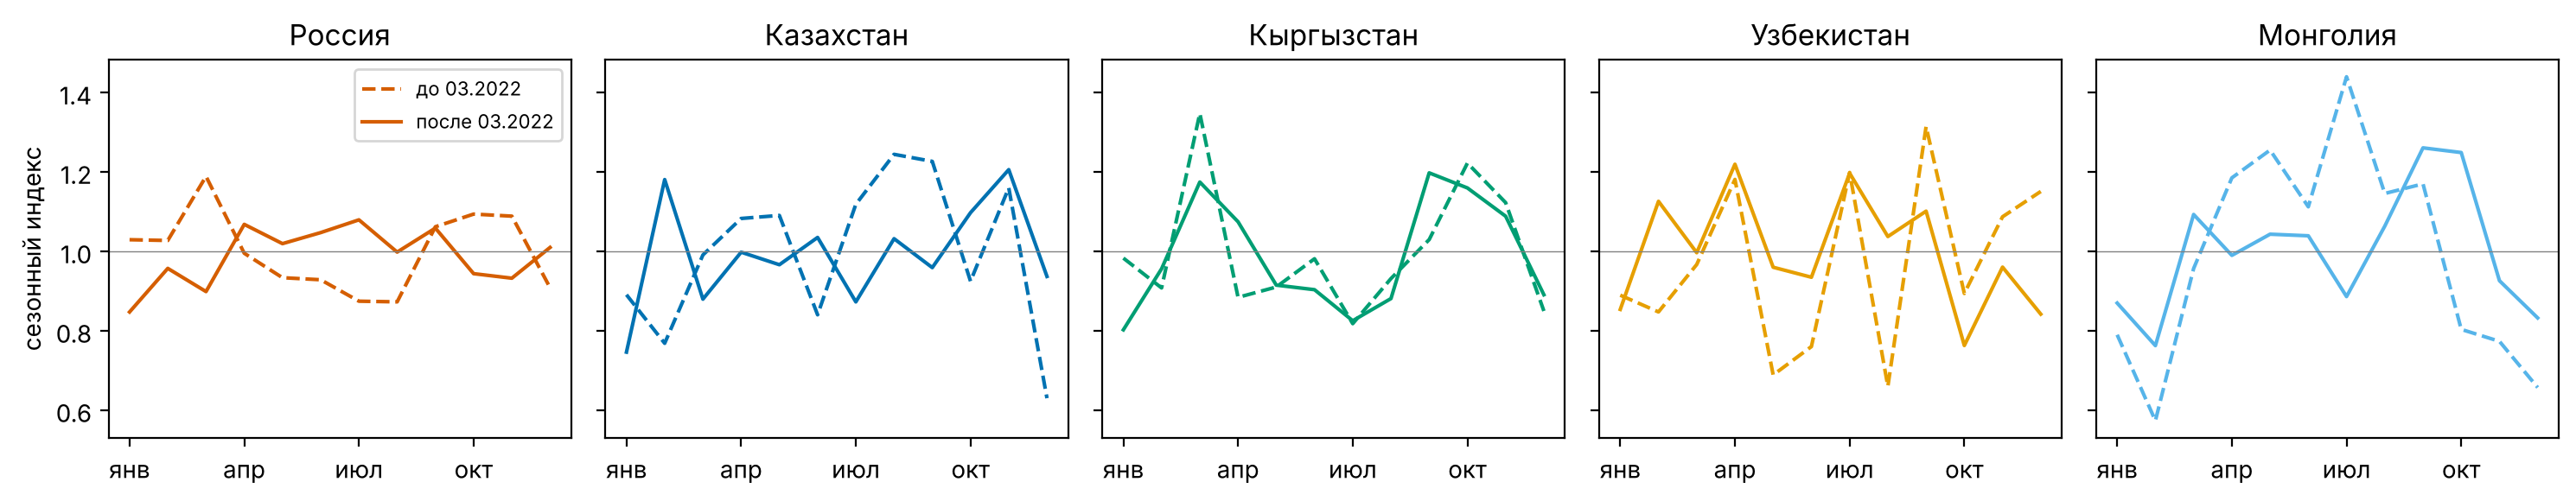

Похожесть профиля до и после 2022 (корреляция): {'Россия': np.float64(-0.6), 'Казахстан': np.float64(0.04), 'Кыргызстан': np.float64(0.72), 'Узбекистан': np.float64(0.36), 'Монголия': np.float64(0.36)}


In [33]:
cmp = si_long.assign(period=np.where(si_long['month'] >= '2022-03', 'после 03.2022', 'до 03.2022'))
cmp = cmp.groupby(['iso2', 'period', 'm'])['si'].mean().unstack('m')
fig, axes = plt.subplots(1, len(SEAS), figsize=(15, 3), sharey=True)
for a, i in zip(axes, SEAS):
    for per, ls in [('до 03.2022', '--'), ('после 03.2022', '-')]:
        a.plot(range(1, 13), cmp.loc[(i, per)], ls=ls, color=PALETTE[i], label=per)
    a.axhline(1, color='grey', lw=.5); a.set_title(name[i]); a.set_xticks([1, 4, 7, 10]); a.set_xticklabels(['янв', 'апр', 'июл', 'окт'])
axes[0].legend(fontsize=8); axes[0].set_ylabel('сезонный индекс')
plt.tight_layout(); plt.savefig(FIG / 'q5a_before_after.png', dpi=150); plt.show()
corr_pp = {name[i]: round(np.corrcoef(cmp.loc[(i, 'до 03.2022')], cmp.loc[(i, 'после 03.2022')])[0, 1], 2) for i in SEAS}
print('Похожесть профиля до и после 2022 (корреляция):', corr_pp)

## 4.4. Корейские праздники: Соллаль и Чусок
Во время праздников в Корее не работают склады и таможня, отгрузки должны проседать в месяц праздника. Проверяем: индекс в месяц Соллаля/Чусока против остальных месяцев.

In [34]:
si_long['seollal'] = (si_long['m'] == si_long['y'].map(SEOLLAL)).astype(int)
si_long['chuseok'] = (si_long['m'] == si_long['y'].map(CHUSEOK)).astype(int)
hol = []
for i in SEAS:
    d = si_long[si_long['iso2'] == i]
    for h in ['seollal', 'chuseok']:
        months_h = d.loc[d[h] == 1, 'm'].unique()
        a_, b_ = d.loc[d[h] == 1, 'si'], d.loc[(d[h] == 0) & d['m'].isin(months_h), 'si']
        hol.append([name[i], 'Соллаль' if h == 'seollal' else 'Чусок', a_.mean(), b_.mean(), stats.ttest_ind(a_, b_, equal_var=False)[1]])
pd.DataFrame(hol, columns=['страна', 'праздник', 'индекс в месяц праздника', 'тот же месяц без праздника', 'p']).round(3)

,страна,праздник,индекс в месяц праздника,тот же месяц без праздника,p
0,Россия,Соллаль,0.951,1.005,0.576
1,Россия,Чусок,0.952,1.137,0.039
2,Казахстан,Соллаль,0.797,0.970,0.260
3,Казахстан,Чусок,0.957,1.153,0.194
4,Кыргызстан,Соллаль,0.849,0.990,0.124
5,Кыргызстан,Чусок,1.035,1.265,0.036
6,Узбекистан,Соллаль,0.895,0.940,0.863
7,Узбекистан,Чусок,1.021,1.035,0.937
8,Монголия,Соллаль,0.652,0.820,0.145
9,Монголия,Чусок,1.137,1.076,0.665


Сравниваем честно: месяц праздника против **того же календарного месяца в годы, когда праздника в нём не было** (Соллаль «прыгает» между январём и февралём, Чусок — между сентябрём и октябрём). Так эффект праздника не путается с обычной сезонностью месяца.

## 4.5. Модель: сезонная регрессия
**Y** = во сколько раз отгрузки месяца выше или ниже среднего за **предыдущие** 12 месяцев (в логарифме): `log(тонны_t / среднее(t−12 … t−1))`. **Признаки:** месяц года (dummy), Соллаль, Чусок, флаг «после 03.2022». Прогноз тонн = среднее за прошлые 12 месяцев × сезонный множитель.

Почему так, а не «тонны ~ тренд + месяц»: первая версия продлевала линейный тренд 2017–2024 и сильно ошибалась на 2025–2026 (у России рост остановился). Опора на уровень последних 12 месяцев использует только прошлое, тренд не «улетает», а коэффициенты при месяцах — это и есть сезонный профиль в %.

**Проверка:** обучение 2017–2024, тест 2025-01 … 2026-10 (прогноз на месяц вперёд). Сравнение с наивной моделью «как в том же месяце год назад» и с «средним за прошлые 12 месяцев без сезонности». Метрики регрессии: MAE (тонн) и MAPE (%).

In [35]:
from sklearn.metrics import mean_absolute_error
mape = lambda y, p: np.mean(np.abs(y - p) / y) * 100
reg_rows, coef_rows = [], []
for i in SEAS:
    d = cc[(cc['iso2'] == i) & (cc['month'] >= '2015-01')][['month', 'tons']].copy()
    d['y'] = d['month'].str[:4].astype(int); d['m'] = d['month'].str[5:].astype(int)
    d['post'] = (d['month'] >= '2022-03').astype(int)
    d['seollal'] = (d['m'] == d['y'].map(SEOLLAL)).astype(int); d['chuseok'] = (d['m'] == d['y'].map(CHUSEOK)).astype(int)
    d['level'] = d['tons'].shift(1).rolling(12).mean()          # среднее за предыдущие 12 месяцев — только прошлое
    d['naive'] = d['tons'].shift(12)
    d = d[(d['month'] >= '2017-01') & (d['tons'] > 0) & (d['level'] > 0)]
    d['ly'] = np.log(d['tons'] / d['level'])
    tr, te = d[d['month'] <= '2024-12'], d[d['month'] >= '2025-01']
    r = smf.ols('ly ~ C(m) + seollal + chuseok + post', tr).fit(cov_type='HC1')
    corr_ = np.exp(np.var(r.resid) / 2)                           # поправка при возврате из логарифма
    pred, pred_tr = te['level'] * np.exp(r.predict(te)) * corr_, tr['level'] * np.exp(r.predict(tr)) * corr_
    reg_rows.append([name[i], mean_absolute_error(tr['tons'], pred_tr), mean_absolute_error(te['tons'], pred), mape(te['tons'], pred),
                     mape(te['tons'], te['naive']), mape(te['tons'], te['level']), r.rsquared])
    co = r.params.filter(like='C(m)'); co.index = [MONTHS_RU[int(k.split('T.')[1][:-1]) - 1] for k in co.index]
    co = pd.concat([pd.Series({'янв': 0.0}), co])
    co = (np.exp(co - co.mean()) - 1) * 100                       # % к среднему месяцу
    co['Соллаль, %'] = (np.exp(r.params['seollal']) - 1) * 100; co['p Соллаль'] = r.pvalues['seollal']
    co['Чусок, %'] = (np.exp(r.params['chuseok']) - 1) * 100; co['p Чусок'] = r.pvalues['chuseok']
    coef_rows.append(co.rename(name[i]))
metrics_5a = pd.DataFrame(reg_rows, columns=['страна', 'MAE train, т', 'MAE test, т', 'MAPE test, %', 'MAPE «как год назад», %',
                                             'MAPE «среднее 12 мес», %', 'R² train']).round(2)
display(metrics_5a)
season_coef = pd.DataFrame(coef_rows).round(2)
season_coef

,страна,"MAE train, т","MAE test, т","MAPE test, %","MAPE «как год назад», %","MAPE «среднее 12 мес», %",R² train
0,Россия,157.91,154.45,14.91,15.38,13.47,0.14
1,Казахстан,41.67,81.62,27.20,29.05,19.63,0.15
2,Кыргызстан,35.52,46.11,17.28,17.24,11.12,0.20
3,Узбекистан,20.18,52.50,32.89,44.02,24.87,0.09
4,Монголия,23.88,82.53,38.41,18.96,21.94,0.29


,янв,фев,мар,апр,май,июн,июл,авг,сен,окт,ноя,дек,"Соллаль, %",p Соллаль,"Чусок, %",p Чусок
Россия,-1.60,6.41,3.49,-0.42,-5.63,-4.23,-7.53,-11.15,21.76,8.38,2.31,-7.55,-9.73,0.42,-19.43,0.05
Казахстан,-4.27,-16.06,-3.65,0.97,3.51,-11.96,-1.72,14.02,50.35,1.38,19.32,-31.12,-15.52,0.51,-37.32,0.04
Кыргызстан,3.64,1.80,35.46,-27.19,-6.15,-6.63,-20.23,-11.11,28.08,27.27,12.16,-15.41,-18.32,0.20,-19.34,0.10
Узбекистан,-20.04,-16.33,-9.19,21.46,-36.57,-13.01,25.32,-33.06,78.07,9.83,21.01,23.70,-18.10,0.83,-18.75,0.41
Монголия,-12.71,-28.23,6.06,13.08,21.09,15.16,21.28,17.46,25.79,-0.73,-20.86,-32.20,-10.91,0.59,-3.62,0.87


## 4.6. Пики отгрузок → файл для календаря запуска

In [36]:
peaks = si_long.groupby(['iso2', 'm'])['si'].mean().rename('seasonal_index').reset_index().rename(columns={'m': 'month_num'})
peaks.to_csv(CLEAN / 'shipment_peaks.csv', index=False, encoding='utf-8-sig')
top = peaks.sort_values('seasonal_index', ascending=False).groupby('iso2').head(2).sort_values(['iso2', 'seasonal_index'], ascending=[True, False])
low = peaks.sort_values('seasonal_index').groupby('iso2').head(2)
summary = pd.DataFrame({
    'пиковые месяцы': top.groupby('iso2').apply(lambda g: ', '.join(f"{MONTHS_RU[m-1]} ({v:.2f})" for m, v in zip(g['month_num'], g['seasonal_index']))),
    'провальные месяцы': low.groupby('iso2').apply(lambda g: ', '.join(f"{MONTHS_RU[m-1]} ({v:.2f})" for m, v in zip(g['month_num'], g['seasonal_index'])))})
summary.index = [name[i] for i in summary.index]
summary

,пиковые месяцы,провальные месяцы
Кыргызстан,"мар (1.26), окт (1.20)","июл (0.82), дек (0.87)"
Казахстан,"ноя (1.18), авг (1.15)","дек (0.77), янв (0.83)"
Монголия,"сен (1.21), июл (1.19)","фев (0.65), дек (0.74)"
Россия,"сен (1.06), мар (1.04)","авг (0.93), дек (0.95)"
Узбекистан,"сен (1.22), апр (1.20)","май (0.81), авг (0.83)"


## 4.7. Выводы по вопросу 5а

1. **У России сезонности отгрузок практически нет:** ANOVA p = 0,89, Краскел–Уоллис p = 0,71, ни одна пара месяцев не отличается по тесту Тьюки. Сезонный индекс всех месяцев — от 0,93 до 1,06. К тому же профиль России после 2022 года поменялся (корреляция «до» и «после» −0,6) — устойчивого «сезона» нет.
2. **Сезонность значима у Кыргызстана и Монголии** (p < 0,001), у Казахстана — на грани (p ≈ 0,06–0,08). Общий рисунок для Центральной Азии и Монголии: **пик в сентябре** (Казахстан +50%, Узбекистан +78%, Монголия +26% к среднему месяцу), **провал в декабре–феврале** (Казахстан −31% в декабре, Монголия −28…−32% в феврале и декабре).
3. **Чусок «съедает» отгрузки** в свой месяц: −19% у России (p = 0,05), −37% у Казахстана (p = 0,04). Высокий сентябрь — это отгрузки **перед** Чусоком, пока не закрылись склады. Соллаль тоже снижает отгрузки (−10…−18%), но незначимо.
4. **Для прогноза сезонность почти бесполезна:** сезонная регрессия не обгоняет простое «среднее за прошлые 12 месяцев» ни в одной стране (MAPE у России 14,9% против 13,5%). Месячные колебания больше сезонных.

**Что делать бренду:** сроки отгрузки в Россию можно планировать без привязки к сезону; в Казахстан, Узбекистан и Монголию — отправлять товар **в августе — начале сентября**, до Чусока, и не планировать отгрузки на месяц Чусока и на декабрь–февраль. **Месяц запуска** определяем не по отгрузкам, а по сезонности спроса (5б) — отгрузки лишь показывают, когда товар физически удобнее везти.

# 5. Вопрос 5б: когда люди больше всего ищут (сезонность спроса)

**Вопрос:** в какие месяцы спрос выше обычного — в целом на корейскую косметику по странам и по категориям продуктов в России. Пик спроса = лучший месяц для запуска и рекламы.

**Данные:**
- Россия — Яндекс Вордстат (файл 05): абсолютное число запросов, 2020-01 … 2026-10; общий запрос, 14 категорий, бренды, ингредиенты;
- Казахстан, Беларусь, Кыргызстан, Узбекистан — Google Trends (файл 01, T01): «корейская косметика», индекс; категорий по месяцам для этих стран нет.

**Данные берём из `data/clean/search_clean.csv`** (подготовила Жулдыз, роль B): синонимы склеены, «1 строка = 0» в Trends, конец периода 2026-10, у ингредиентов убрано «для лица». Для сезонности берём: Россия — все ряды Вордстата (`export_id = ws`), остальные страны — общий запрос «корейская косметика» на одной шкале (`T01`). Ряды с долей нулей > 50% не используем.

**Метод тот же, что в 5а:** сезонный индекс = значение месяца ÷ центрированное скользящее среднее за 12 месяцев.

In [37]:
if not (CLEAN / 'search_clean.csv').exists():
    raise FileNotFoundError('Нужен data/clean/search_clean.csv от роли B (Жулдыз, ветка b-demand). '
                            'Слейте b-demand в main или запустите build_B_clean.py.')
search = pd.read_csv(CLEAN / 'search_clean.csv', encoding='utf-8-sig')
search = search[search['export_id'].isin(['ws', 'T01']) & (search['zero_share'] <= 0.5)]
search = search[['source', 'geo', 'term', 'group', 'month', 'value', 'zero_share']]
print('рядов:', search.groupby(['geo', 'term']).ngroups, '| месяцев:', search['month'].nunique(), search['month'].min(), '…', search['month'].max())
search.groupby(['geo', 'group'])['term'].nunique().unstack(fill_value=0)

рядов: 58 | месяцев: 82 2020-01 … 2026-10


group,brand,category,general,ingredient
geo,,,,
BY,0,0,1,0
KG,0,0,1,0
KZ,0,0,1,0
RU,15,13,1,25
UZ,0,0,1,0


In [38]:
def seasonal_index(s):
    ma = s.rolling(12, center=True).mean(); ma = (ma + ma.shift(-1)) / 2
    return s / ma

piv = search.pivot_table(index='month', columns=['geo', 'term', 'group'], values='value')
SI = piv.apply(seasonal_index).dropna(how='all')
SI_long = SI.stack(['geo', 'term', 'group'], future_stack=True).rename('si').reset_index().dropna()
SI_long['m'] = SI_long['month'].str[5:].astype(int)
prof = SI_long.groupby(['geo', 'term', 'group', 'm'])['si'].mean().unstack('m'); prof.columns = MONTHS_RU
print('сезонный индекс считается за', SI.index.min(), '…', SI.index.max())

сезонный индекс считается за 2020-07 … 2026-04


## 5.1. Общий спрос на корейскую косметику по странам
Россия — Вордстат, остальные — Google Trends. Сравниваем **форму** сезонности (индекс относительно своего среднего), уровни у источников разные.

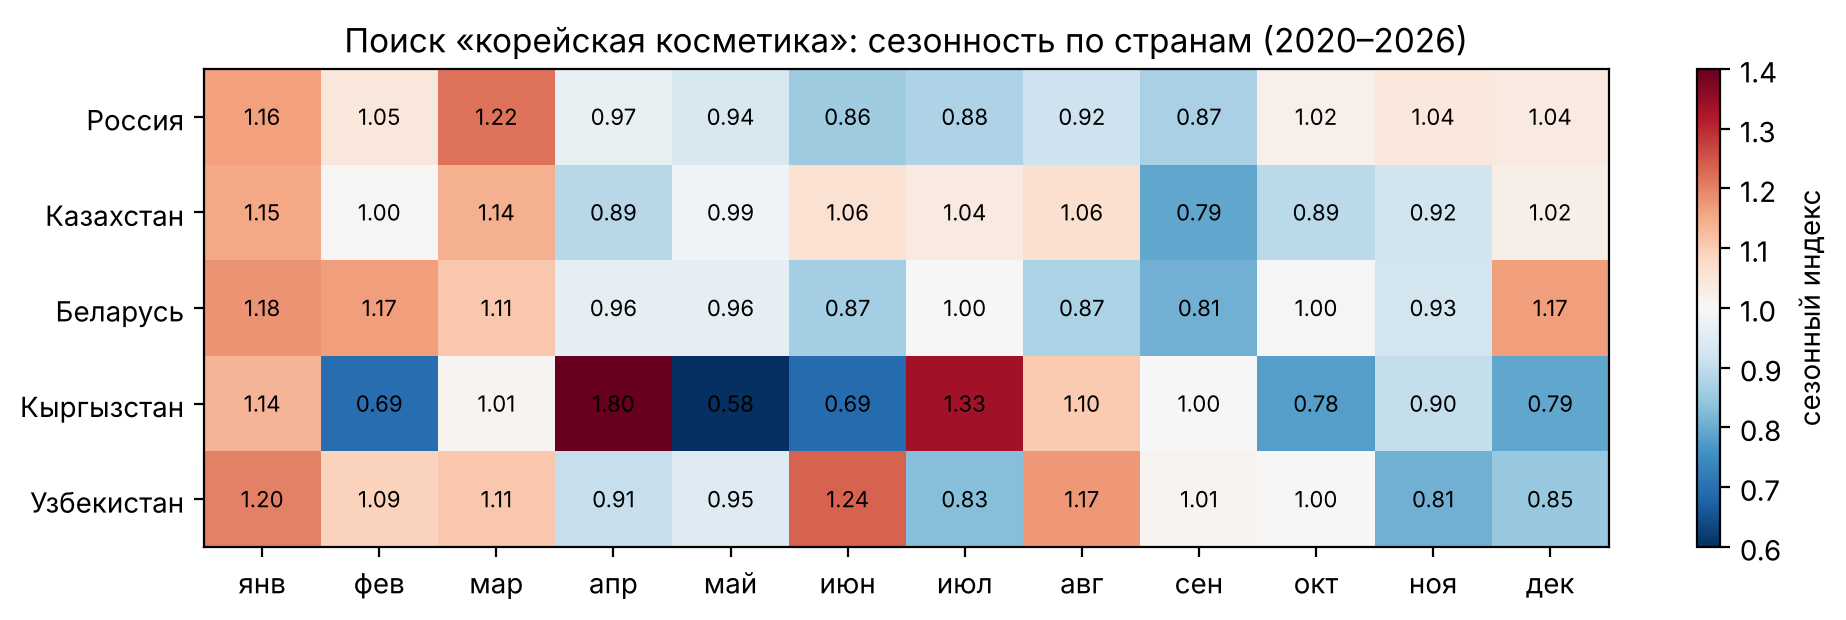

,янв,фев,мар,апр,май,июн,июл,авг,сен,окт,ноя,дек
Россия,1.16,1.05,1.22,0.97,0.94,0.86,0.88,0.92,0.87,1.02,1.04,1.04
Казахстан,1.15,1.00,1.14,0.89,0.99,1.06,1.04,1.06,0.79,0.89,0.92,1.02
Беларусь,1.18,1.17,1.11,0.96,0.96,0.87,1.00,0.87,0.81,1.00,0.93,1.17
Кыргызстан,1.14,0.69,1.01,1.80,0.58,0.69,1.33,1.10,1.00,0.78,0.90,0.79
Узбекистан,1.20,1.09,1.11,0.91,0.95,1.24,0.83,1.17,1.01,1.00,0.81,0.85


In [39]:
gen = prof.xs('корейская косметика', level='term').droplevel('group')
gen = gen.reindex(['RU', 'KZ', 'BY', 'KG', 'UZ']); gen.index = [name.get(i, i) for i in gen.index]
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(gen.values, cmap='RdBu_r', vmin=0.6, vmax=1.4, aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS_RU); ax.set_yticks(range(len(gen))); ax.set_yticklabels(gen.index)
for r in range(gen.shape[0]):
    for c in range(12): ax.text(c, r, f'{gen.values[r, c]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax, label='сезонный индекс')
ax.set_title('Поиск «корейская косметика»: сезонность по странам (2020–2026)')
plt.tight_layout(); plt.savefig(FIG / 'q5b_general_by_country.png', dpi=150); plt.show()
gen.round(2)

## 5.2. Категории в России: что и когда ищут

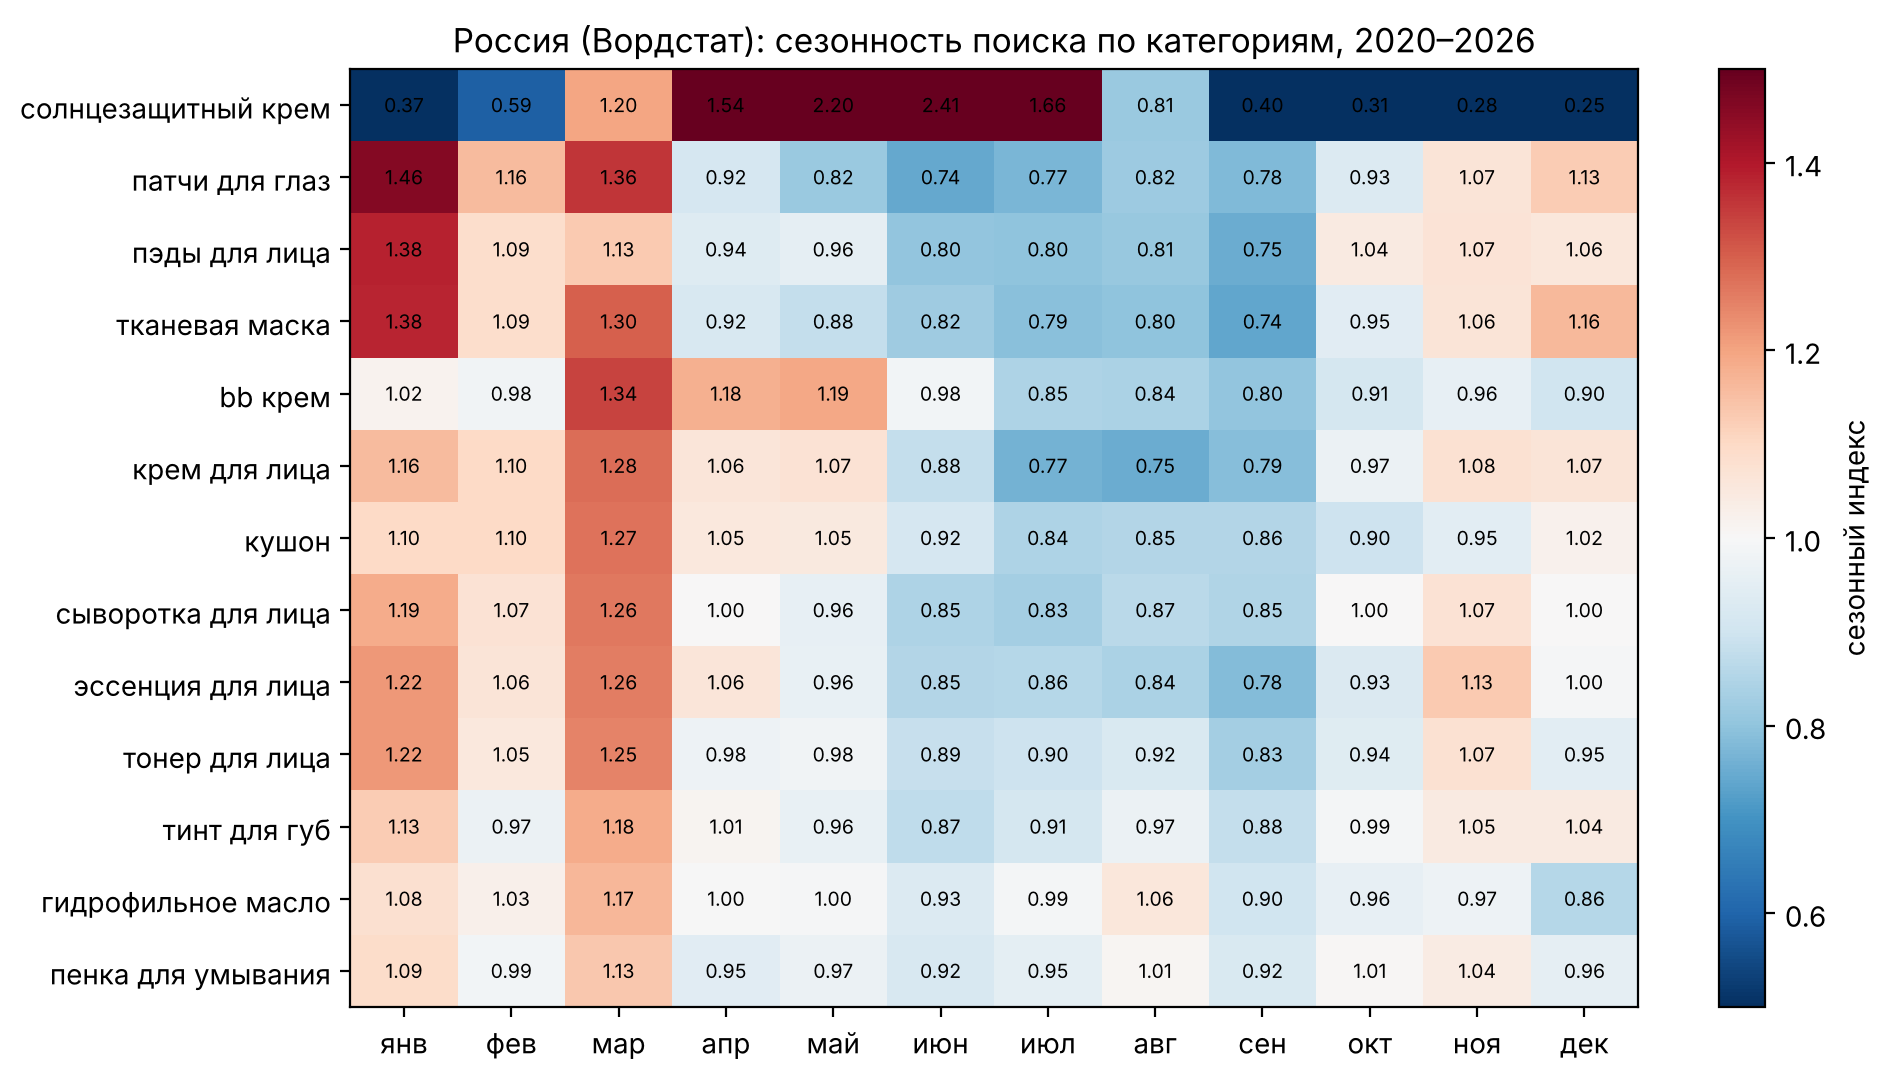

In [40]:
cat = prof.xs(('RU', 'category'), level=('geo', 'group'))
cat = cat.loc[cat.max(axis=1).sort_values(ascending=False).index]          # самые сезонные сверху
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(cat.values, cmap='RdBu_r', vmin=0.5, vmax=1.5, aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS_RU); ax.set_yticks(range(len(cat))); ax.set_yticklabels(cat.index)
for r in range(cat.shape[0]):
    for c in range(12): ax.text(c, r, f'{cat.values[r, c]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, label='сезонный индекс')
ax.set_title('Россия (Вордстат): сезонность поиска по категориям, 2020–2026')
plt.tight_layout(); plt.savefig(FIG / 'q5b_categories_ru.png', dpi=150); plt.show()

## 5.3. Значимость сезонности (ANOVA + Краскел–Уоллис) и пиковые месяцы

In [41]:
rows = []
for (geo, term, group), d in SI_long.groupby(['geo', 'term', 'group']):
    g = [x['si'].values for _, x in d.groupby('m')]
    F, pa = stats.f_oneway(*g); H, pk = stats.kruskal(*g)
    p = prof.loc[(geo, term, group)]
    rows.append([geo, term, group, p.idxmax(), p.max(), p.idxmin(), p.min(), p.max() - p.min(), pa, pk])
sig = pd.DataFrame(rows, columns=['geo', 'term', 'group', 'пик', 'индекс пика', 'провал', 'индекс провала', 'амплитуда', 'p ANOVA', 'p Kruskal'])
sig['сезонность значима'] = (sig['p ANOVA'] < 0.05) & (sig['p Kruskal'] < 0.05)
print('Доля рядов со значимой сезонностью:', round(sig['сезонность значима'].mean() * 100), '%')
show = sig[(sig['group'].isin(['general', 'category']))].sort_values('амплитуда', ascending=False)
show.round(3)

Доля рядов со значимой сезонностью: 84 %


,geo,term,group,пик,индекс пика,провал,индекс провала,амплитуда,p ANOVA,p Kruskal,сезонность значима
45,RU,солнцезащитный крем,category,июн,2.410,дек,0.247,2.163,0.000,0.000,True
1,KG,корейская косметика,general,апр,1.797,май,0.584,1.213,0.354,0.423,False
36,RU,патчи для глаз,category,янв,1.458,июн,0.745,0.713,0.000,0.000,True
49,RU,тканевая маска,category,янв,1.382,сен,0.742,0.640,0.000,0.000,True
41,RU,пэды для лица,category,янв,1.384,сен,0.753,0.631,0.000,0.000,True
4,RU,bb крем,category,мар,1.337,сен,0.803,0.534,0.000,0.000,True
30,RU,крем для лица,category,мар,1.279,авг,0.751,0.528,0.000,0.000,True
56,RU,эссенция для лица,category,мар,1.258,сен,0.782,0.476,0.000,0.000,True
47,RU,сыворотка для лица,category,мар,1.262,июл,0.830,0.432,0.000,0.000,True
57,UZ,корейская косметика,general,июн,1.236,ноя,0.807,0.429,0.475,0.448,False


## 5.4. Модель: сезонная регрессия спроса
Та же постановка, что в 5а: **Y** = log(значение месяца ÷ среднее за предыдущие 12 месяцев), признаки — месяц года (dummy). Учим на 2020–2024, проверяем на 2025-01 … 2026-10; сравниваем со «средним за прошлые 12 месяцев» и «как год назад». Если сезонная модель выигрывает — сезонность спроса реальная и пригодна для планирования запуска.

In [42]:
def seasonal_model(s):
    d = pd.DataFrame({'v': s.values}, index=s.index)
    d['m'] = d.index.str[5:].astype(int); d['level'] = d['v'].shift(1).rolling(12).mean(); d['naive'] = d['v'].shift(12)
    d = d[(d['v'] > 0) & (d['level'] > 0)].copy(); d['ly'] = np.log(d['v'] / d['level'])
    tr, te = d[d.index <= '2024-12'], d[d.index >= '2025-01']
    if len(tr) < 24 or len(te) < 6: return None
    r = smf.ols('ly ~ C(m)', tr).fit(); k = np.exp(np.var(r.resid) / 2)
    pred = te['level'] * np.exp(r.predict(te)) * k
    ok = te['naive'] > 0
    return mape(te['v'], pred), mape(te['v'][ok], te['naive'][ok]), mape(te['v'], te['level'])

res = []
for (geo, term, group) in piv.columns:
    if (geo, term) not in set(zip(search['geo'], search['term'])): continue
    out = seasonal_model(piv[(geo, term, group)].dropna())
    if out: res.append([geo, term, group, *out])
sm = pd.DataFrame(res, columns=['geo', 'term', 'group', 'MAPE сезонная', 'MAPE «как год назад»', 'MAPE «среднее 12 мес»'])
sm['сезонная лучше'] = sm['MAPE сезонная'] < sm[['MAPE «как год назад»', 'MAPE «среднее 12 мес»']].min(axis=1)
print('Сезонная модель лучше обеих простых: %d из %d рядов' % (sm['сезонная лучше'].sum(), len(sm)))
display(sm.groupby('group')[['MAPE сезонная', 'MAPE «как год назад»', 'MAPE «среднее 12 мес»', 'сезонная лучше']].mean().round(2))
sm[sm['group'].isin(['general', 'category'])].sort_values('MAPE сезонная').round(1)

Сезонная модель лучше обеих простых: 28 из 58 рядов


,MAPE сезонная,MAPE «как год назад»,MAPE «среднее 12 мес»,сезонная лучше
group,,,,
brand,44.23,35.49,24.01,0.20
category,14.07,18.12,20.24,0.54
general,23.32,27.32,24.41,0.60
ingredient,22.98,28.38,19.63,0.60


,geo,term,group,MAPE сезонная,MAPE «как год назад»,MAPE «среднее 12 мес»,сезонная лучше
49,RU,тканевая маска,category,8.0,13.6,19.7,True
36,RU,патчи для глаз,category,8.7,16.5,18.8,True
29,RU,корейская косметика,general,9.8,23.2,14.2,True
50,RU,тонер для лица,category,10.2,14.6,13.1,True
30,RU,крем для лица,category,10.5,11.1,10.6,True
4,RU,bb крем,category,11.3,16.6,12.6,True
47,RU,сыворотка для лица,category,11.4,11.4,10.8,False
37,RU,пенка для умывания,category,11.6,12.2,9.6,False
56,RU,эссенция для лица,category,14.3,16.1,18.1,True
48,RU,тинт для губ,category,17.0,22.6,15.9,False


## 5.5. Типы сезонности: кластеризация профилей (K-Means)
Каждый ряд описываем 12 числами (сезонный индекс по месяцам) и группируем похожие формы. Берём только ряды со значимой сезонностью. Число кластеров выбираем по силуэту.

силуэт по k: {2: 0.66, 3: 0.481, 4: 0.233, 5: 0.26}


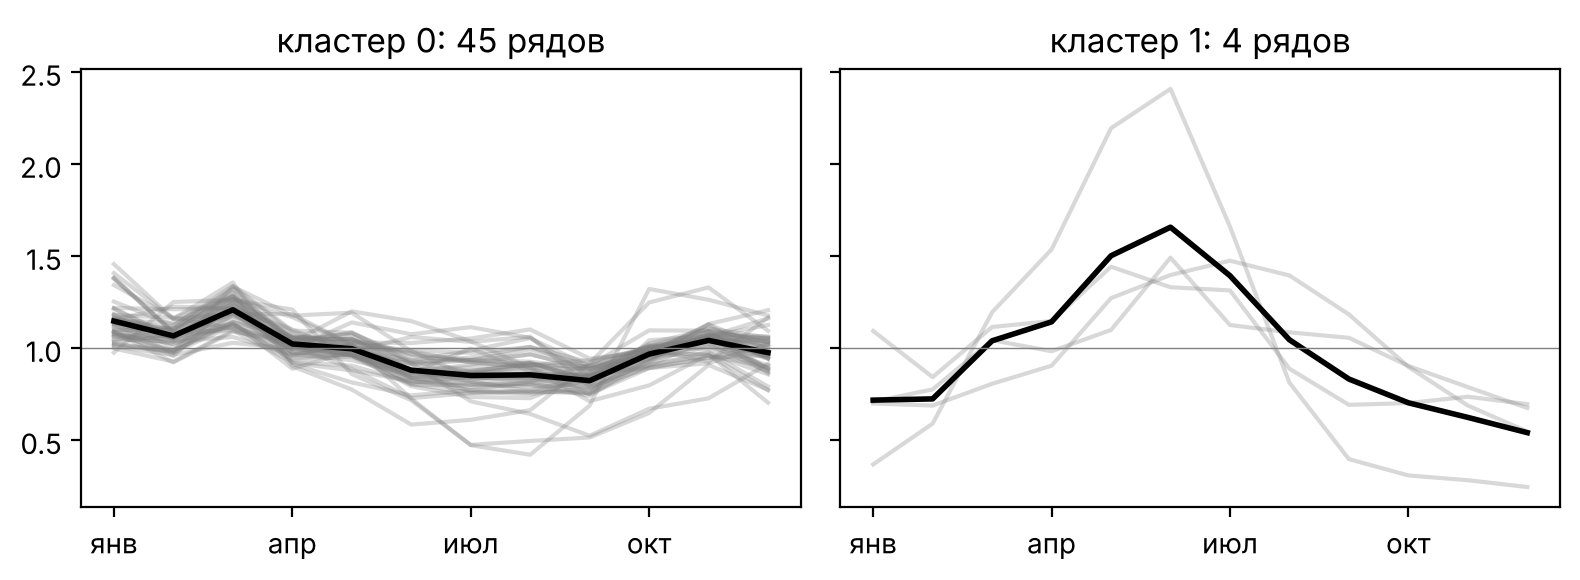

кластер 0, пик: мар | ряды: корейская косметика, корейская косметика, bb крем, cosrx, dr jart, innisfree, laneige, manyo, missha, pdrn, round lab, some by mi, torriden, бакучиол, витамин с, галактомисис, гиалуроновая кислота, гидрофильное масло, женьшень, керамиды, коллаген, корейская косметика, крем для лица, кушон, муцин улитки, ниацинамид, пантенол, патчи для глаз, пенка для умывания, пептиды, полынь, прополис, пэды для лица, ретинол, рис, салициловая кислота, спикулы, сыворотка для лица, тинт для губ, тканевая маска, тонер для лица, центелла, чайное дерево, экзосомы, эссенция для лица
кластер 1, пик: июн | ряды: beauty of joseon, солнцезащитный крем, транексамовая кислота, хауттюйния


In [43]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
keys = sig.loc[sig['сезонность значима'], ['geo', 'term', 'group']].apply(tuple, axis=1)
P = prof.loc[list(keys)]
sil = {k: silhouette_score(P, KMeans(k, n_init=20, random_state=42).fit_predict(P)) for k in range(2, 6)}
print('силуэт по k:', {k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get)
km = KMeans(K, n_init=20, random_state=42).fit(P)
P = P.assign(cluster=km.labels_)
fig, axes = plt.subplots(1, K, figsize=(4 * K, 3), sharey=True)
for c, a in zip(range(K), np.atleast_1d(axes)):
    members = P[P['cluster'] == c].drop(columns='cluster')
    for _, row in members.iterrows(): a.plot(range(1, 13), row.values, color='grey', alpha=.3)
    a.plot(range(1, 13), km.cluster_centers_[c], color='k', lw=2)
    a.axhline(1, color='grey', lw=.5); a.set_xticks([1, 4, 7, 10]); a.set_xticklabels(['янв', 'апр', 'июл', 'окт'])
    a.set_title(f'кластер {c}: {len(members)} рядов')
plt.tight_layout(); plt.savefig(FIG / 'q5b_season_clusters.png', dpi=150); plt.show()
for c in range(K):
    print(f'кластер {c}, пик:', MONTHS_RU[int(np.argmax(km.cluster_centers_[c]))], '| ряды:', ', '.join(t for (_, t, _) in P[P['cluster'] == c].index))

## 5.6. Пики спроса → файл для календаря запуска

In [44]:
search_peaks = sig[['geo', 'term', 'group', 'пик', 'индекс пика', 'провал', 'амплитуда', 'сезонность значима']].copy()
search_peaks['peak_month_num'] = search_peaks['пик'].map({m: i + 1 for i, m in enumerate(MONTHS_RU)})
search_peaks.to_csv(CLEAN / 'search_peaks.csv', index=False, encoding='utf-8-sig')
print(CLEAN / 'search_peaks.csv', search_peaks.shape)

../data/clean/search_peaks.csv (58, 9)


## 5.7. Выводы по вопросу 5б

1. **Спрос на корейскую косметику сезонный, в отличие от отгрузок.** Сезонность значима у 84% поисковых рядов (ANOVA и Краскел–Уоллис, p < 0,05).
2. **По странам:** Россия — пик в **марте** (1,22) и январе (1,16), провал летом (июнь 0,86); Казахстан и Беларусь — пик в **январе** (1,15–1,18), провал в сентябре (0,79–0,81). У Кыргызстана и Узбекистана сезонность незначима — ряды Trends слишком шумные.
3. **По категориям в России — два типа сезонности** (K-Means, силуэт 0,66 при k = 2):
   - **«весенний» (большинство):** кремы, сыворотки, тонеры, кушоны, BB-кремы, тинты — пик в **марте** (8 Марта и обновление ухода после зимы), спад в июле–сентябре;
   - **«летний»:** солнцезащитный крем — пик в **июне**, в 2,4 раза выше обычного, а в декабре в 4 раза ниже; к нему же тяготеют транексамовая кислота (осветление) и хауттюйния.
   - Отдельно **маски, патчи и пэды — пик в январе** (новогодние подарки и зимний уход).
4. **Сезонность пригодна для планирования:** для категорий сезонная модель точнее простых в половине рядов, а для «корейской косметики» в России — заметно (MAPE 9,8% против 14,2% у «среднего за 12 месяцев»). Для брендов нет: их спрос определяется трендом, а не сезоном.

**Что делать бренду:** запуск уходовой линейки в России — **в феврале**, чтобы успеть к пику в марте; маски и патчи — в **декабре** к январскому пику; солнцезащита — в **апреле–мае** к пику в июне. В Казахстане и Беларуси главный месяц спроса — **январь**, запуск — в **декабре**. Точные месяцы отгрузки сведём в календаре с учётом того, на сколько месяцев поиск опережает экспорт (вопрос 2).

# 6. Итоговый календарь запуска

Собираем ответ «**когда**» для стратегии: для каждой страны и категории — месяц отгрузки из Кореи, месяц запуска и месяц пика спроса.

**Правила:**
1. **Пик спроса** — месяц с максимальным сезонным индексом поиска (5б).
2. **Запуск = за 1 месяц до пика:** товар уже на полках и реклама идёт, когда спрос растёт к пику.
3. **Отгрузка = запуск − срок поставки.** Срок берём из вопроса 2 (файл `lead_lag.csv`, роль B): на сколько месяцев поиск опережает отгрузки. Используем его только там, где связь подтверждена (уверенность не «низкая») — это **Казахстан, 2 месяца**. Для остальных стран связь не найдена, поэтому берём допущение `LEAD = 2` месяца: доставка морем или по железной дороге ~1–1,5 месяца плюс таможня и маркировка «Честный знак».
4. **Поправка по отгрузкам (5а):** для Казахстана и Беларуси отгрузка не ставится на декабрь–февраль (зимний провал отгрузок) — переносим на ноябрь; если отгрузка попадает на сентябрь–октябрь, помечаем «отправить до Чусока».
5. **Если сезонность незначима** (Кыргызстан, Узбекистан) — запуск без привязки к месяцу, ориентир — общий пик соседних рынков.
6. **Что вырастет** (вопрос 4, файл `growth_candidates.csv` от роли C) — добавляется колонкой, когда файл будет готов.

In [45]:
LEAD = 2
lag_file = CLEAN / 'lead_lag.csv'
lead_by_geo, trust_by_geo = {}, {}
if lag_file.exists():
    lead_lag = pd.read_csv(lag_file)
    print('лаг поиск → экспорт из вопроса 2:'); display(lead_lag[['iso2', 'best_lag', 'r_test', 'mae_change_pct', 'granger_p', 'trust']])
    for _, r in lead_lag.iterrows():
        trust_by_geo[r['iso2']] = r['trust']
        lead_by_geo[r['iso2']] = int(r['best_lag']) if r['trust'] != 'низкая' else LEAD
else:
    print('lead_lag.csv ещё нет — используем LEAD =', LEAD)

sp = pd.read_csv(CLEAN / 'search_peaks.csv', encoding='utf-8-sig')
items = sp[(sp['group'] == 'category') | ((sp['group'] == 'general'))].copy()
mshift = lambda m, k: (m - 1 + k) % 12 + 1

items['пик'] = items['peak_month_num']
items['запуск'] = items['пик'].apply(lambda m: mshift(m, -1))
items['срок поставки, мес.'] = items['geo'].map(lambda g: lead_by_geo.get(g, LEAD))
items['источник срока'] = items['geo'].map(lambda g: 'лаг из вопроса 2' if trust_by_geo.get(g, 'низкая') != 'низкая' else 'допущение (логистика)')
items['уверенность в поиске'] = items['geo'].map(lambda g: trust_by_geo.get(g, '—'))
items['отгрузка'] = [mshift(m, -k) for m, k in zip(items['запуск'], items['срок поставки, мес.'])]
note = []
for _, r in items.iterrows():
    n = []
    if not r['сезонность значима']:
        n.append('сезон не выражен — запуск в любой месяц')
    if r['geo'] in ('KZ', 'BY'):
        if r['отгрузка'] in (12, 1, 2):
            items.loc[_, 'отгрузка'] = 11; n.append('отгрузка перенесена на ноябрь (зимний провал отгрузок)')
        if items.loc[_, 'отгрузка'] in (9, 10):
            n.append('отправить до Чусока')
    note.append('; '.join(n))
items['примечание'] = note
items['страна'] = items['geo'].map(lambda g: name.get(g, g))
items['категория'] = np.where(items['group'] == 'general', 'корейская косметика (в целом)', items['term'])
SEASON = {12: 'зимний', 1: 'зимний', 2: 'зимний', 3: 'весенний', 4: 'весенний', 5: 'весенний',
          6: 'летний', 7: 'летний', 8: 'летний', 9: 'осенний', 10: 'осенний', 11: 'осенний'}
items['тип сезона'] = np.where(items['сезонность значима'], items['пик'].map(SEASON), 'не выражен')
for c_ in ['пик', 'запуск', 'отгрузка']:
    items[c_ + ' (мес.)'] = items[c_].map(lambda m: MONTHS_RU[m - 1])

growth_file = CLEAN / 'growth_candidates.csv'
if growth_file.exists():
    gc = pd.read_csv(growth_file)
    items = items.merge(gc[['geo', 'term', 'p_grow_12m']], on=['geo', 'term'], how='left')
order = {'RU': 0, 'KZ': 1, 'BY': 2, 'KG': 3, 'UZ': 4}
cal = items.sort_values(['geo', 'пик'], key=lambda s: s.map(order) if s.name == 'geo' else s)
cols = ['страна', 'категория', 'тип сезона', 'отгрузка (мес.)', 'запуск (мес.)', 'пик (мес.)', 'индекс пика', 'срок поставки, мес.', 'источник срока', 'уверенность в поиске', 'примечание'] + \
       (['p_grow_12m'] if 'p_grow_12m' in cal else [])
calendar_out = cal[cols].reset_index(drop=True)
calendar_out.to_csv(CLEAN / 'launch_calendar.csv', index=False, encoding='utf-8-sig')
calendar_out.round(2)

лаг поиск → экспорт из вопроса 2:


,iso2,best_lag,r_test,mae_change_pct,granger_p,trust
0,RU,6,-0.064,0.4,0.423,низкая
1,KZ,2,0.369,-13.8,0.004,средняя
2,BY,2,-0.091,9.3,0.095,низкая
3,KG,3,0.138,15.7,0.144,низкая
4,UZ,2,-0.404,26.5,0.277,низкая


,страна,категория,тип сезона,отгрузка (мес.),запуск (мес.),пик (мес.),индекс пика,"срок поставки, мес.",источник срока,уверенность в поиске,примечание
0,Россия,патчи для глаз,зимний,окт,дек,янв,1.46,2,допущение (логистика),низкая,
1,Россия,пэды для лица,зимний,окт,дек,янв,1.38,2,допущение (логистика),низкая,
2,Россия,тканевая маска,зимний,окт,дек,янв,1.38,2,допущение (логистика),низкая,
3,Россия,bb крем,весенний,дек,фев,мар,1.34,2,допущение (логистика),низкая,
4,Россия,гидрофильное масло,весенний,дек,фев,мар,1.17,2,допущение (логистика),низкая,
5,Россия,корейская косметика (в целом),весенний,дек,фев,мар,1.22,2,допущение (логистика),низкая,
6,Россия,крем для лица,весенний,дек,фев,мар,1.28,2,допущение (логистика),низкая,
7,Россия,кушон,весенний,дек,фев,мар,1.27,2,допущение (логистика),низкая,
8,Россия,пенка для умывания,весенний,дек,фев,мар,1.13,2,допущение (логистика),низкая,
9,Россия,сыворотка для лица,весенний,дек,фев,мар,1.26,2,допущение (логистика),низкая,


## 6.1. Календарь на одной картинке
По строкам — страна и категория, по столбцам — месяцы. ▲ — отгрузка из Кореи, ● — запуск, ★ — пик спроса; заливка — сила сезона (сезонный индекс поиска).

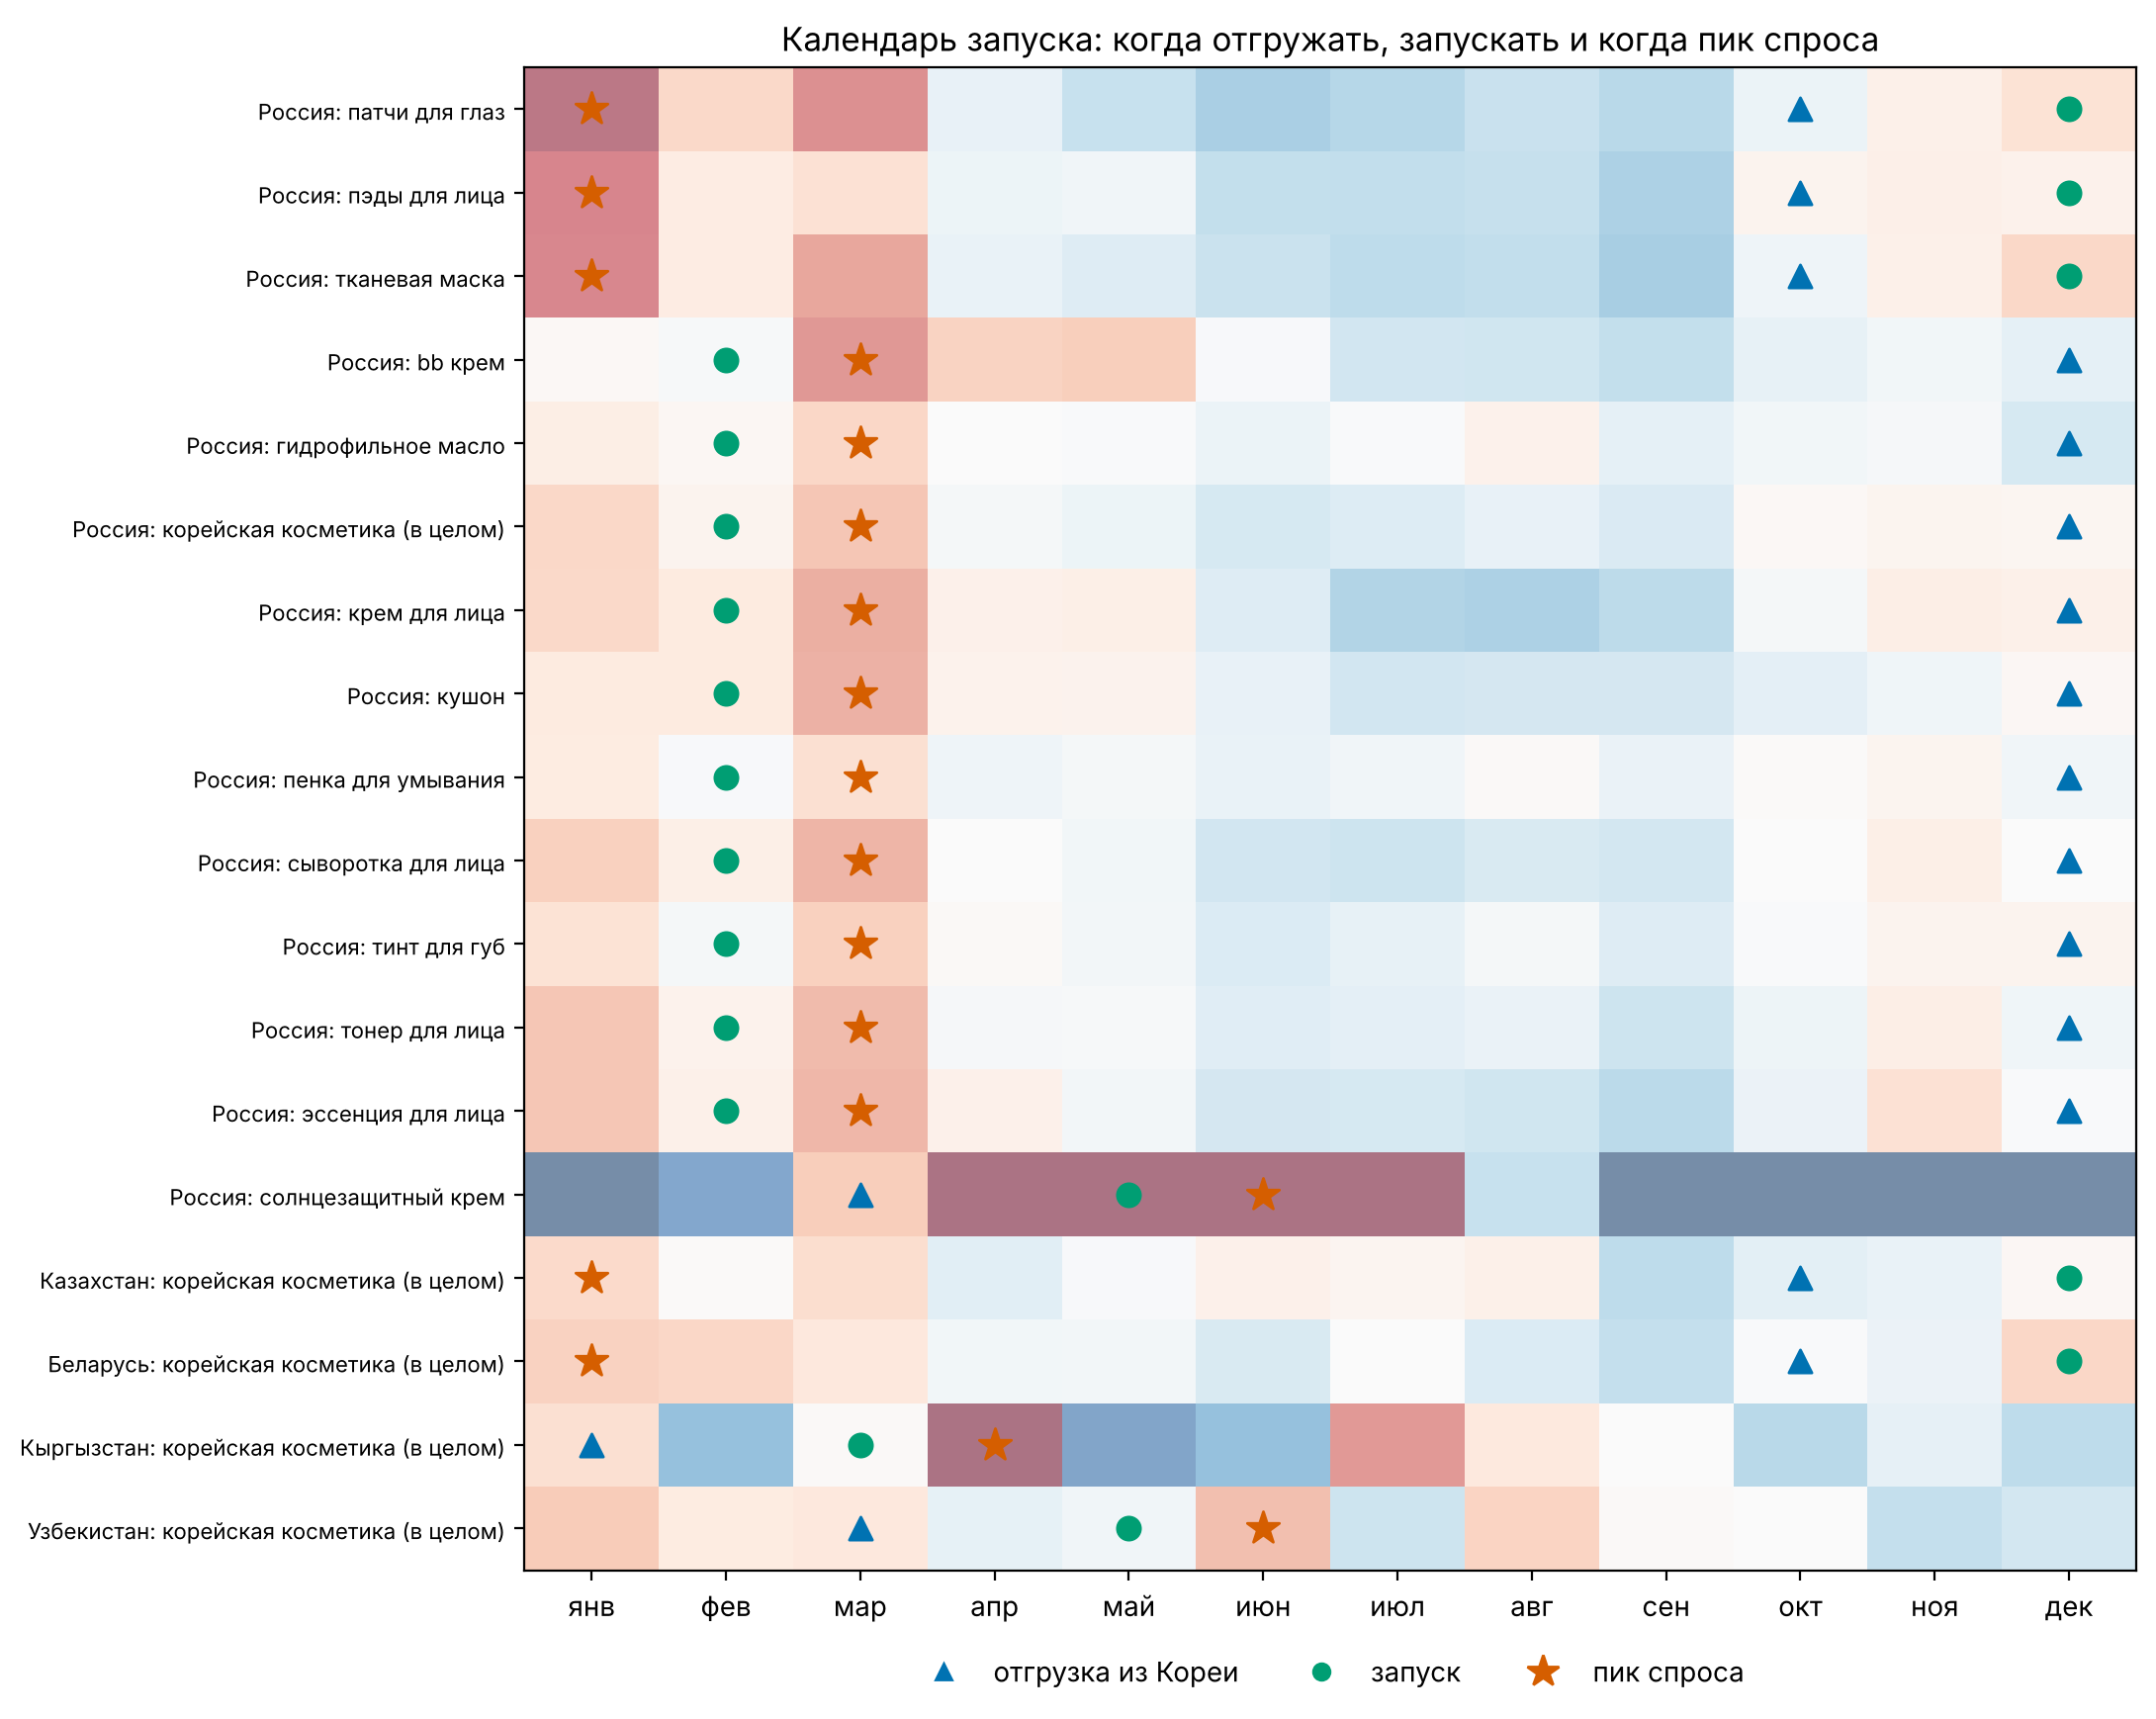

In [46]:
rows = cal.reset_index(drop=True)
labels_ = [f"{r['страна']}: {r['категория']}" for _, r in rows.iterrows()]
fig, ax = plt.subplots(figsize=(11, 0.42 * len(rows) + 1.2))
grid = np.array([prof.loc[(g, t, grp)].values for g, t, grp in zip(rows['geo'], rows['term'], rows['group'])])
ax.imshow(grid, cmap='RdBu_r', vmin=0.5, vmax=1.5, aspect='auto', alpha=.55)
for i, r in rows.iterrows():
    ax.scatter(r['отгрузка'] - 1, i, marker='^', s=70, color='#0072B2', zorder=3)
    ax.scatter(r['запуск'] - 1, i, marker='o', s=70, color='#009E73', zorder=3)
    ax.scatter(r['пик'] - 1, i, marker='*', s=150, color='#D55E00', zorder=3)
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS_RU); ax.set_yticks(range(len(rows))); ax.set_yticklabels(labels_, fontsize=8)
from matplotlib.lines import Line2D
ax.legend([Line2D([], [], marker='^', ls='', color='#0072B2'), Line2D([], [], marker='o', ls='', color='#009E73'),
           Line2D([], [], marker='*', ls='', color='#D55E00', ms=12)], ['отгрузка из Кореи', 'запуск', 'пик спроса'],
          loc='upper center', bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False)
ax.set_title('Календарь запуска: когда отгружать, запускать и когда пик спроса')
plt.tight_layout(); plt.savefig(FIG / 'q5_launch_calendar.png', dpi=150, bbox_inches='tight'); plt.show()

## 6.2. Выводы: календарь запуска

| Что запускаем | Где | Отгрузка из Кореи | Запуск | Пик спроса |
|---|---|---|---|---|
| Маски, патчи, пэды | Россия | октябрь | декабрь | январь (индекс 1,38–1,46) |
| Основной уход: кремы, сыворотки, тонеры, эссенции, кушоны, BB, тинты, пенки | Россия | декабрь | февраль | март (1,13–1,34) |
| Солнцезащита | Россия | март | май | июнь (2,41 — самый сильный сезон) |
| Корейская косметика в целом | Казахстан, Беларусь | октябрь, до Чусока | декабрь | январь (1,15–1,18) |
| Корейская косметика в целом | Кыргызстан, Узбекистан | — | любой месяц | сезон незначим |

**Что делать бренду:** год строится из трёх волн. **Зимняя** — маски и патчи в России к Новому году, плюс вход в Казахстан и Беларусь к январскому пику; отгрузка в октябре, до Чусока. **Весенняя** — главная: основной уход в России к марту (8 Марта и весеннее обновление ухода), отгрузка в декабре, запуск в феврале. **Летняя** — солнцезащита: запуск в мае к июньскому пику, когда спрос в 2,4 раза выше обычного месяца. **Насколько календарю можно доверять:** для **Казахстана** срок 2 месяца подтверждён данными — поиск опережает отгрузки на 2 месяца (вопрос 2: Грейнджер p = 0,004, поиск улучшает прогноз отгрузок на 14%), уверенность средняя. Для **России** связь между поиском и отгрузками не найдена: месяцы запуска опираются на сильную и устойчивую сезонность спроса (5б), а срок отгрузки 2 месяца — логистическое допущение. Для Беларуси, Кыргызстана и Узбекистана — уверенность низкая, календарь там ориентировочный.